# Molecular dynamics of Lennard-Jones particles
### A guided programming case study

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 14 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/14_Molecular_Dynamics_Efficient_Computing.ipynb)

This case study is intended for demonstrating applications of programming.

In molecular dynamics (MD), a computer repeatedly calculates the forces on particles and uses Newton's laws to predict their next positions and velocities. We will build a small, deliberately simplified model and use its output to practise elementary data analysis.

No previous knowledge of MD or molecular interactions is assumed. Basic algebra, vectors, Newton's second law, and introductory Python are sufficient. Run cells **from top to bottom** using *Run All*. The notebook uses only NumPy and Matplotlib. On a local machine, install them with `python -m pip install numpy matplotlib` if necessary. A fresh run takes roughly half a minute on a typical laptop or in Google Colab.


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 5, Efficiency |
| **Time** | about 80 min; about 45 min if you skip the repeated material |
| **Before this** | Notebook 13. |
| **Essential** | The "Efficient computing" boxes E1–E4, then Sections 6 and 8, and the checklist in Section 11. |
| **Optional on a first reading** | The sections repeated from notebook 13 (1–5, 7, 9, 10). |
| **Next** | 15, The brachistochrone. |

**You have understood this notebook if you can, without looking back:**

1. Measure where a program spends its time before trying to speed it up.
2. Explain the memory difference between updating an array in place and creating a new one.
3. Check a faster routine against the original to round-off, and explain why the trajectories still drift apart.
4. Explain why the cost of all-pairs forces grows as N², and estimate the run time for a larger system.
5. Say when NumPy is faster than a plain loop and when, for tiny arrays, it is not.

**Not expected of you:** Writing the fast version yourself from scratch.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## What you will learn

By the end, you should be able to explain (1) how a pair interaction produces a force, (2) why the force on one particle has an equal and opposite partner, (3) how a small time step advances Newton's equations, (4) how temperature and energy are calculated from the resulting numerical data, and (5) how choices of units, formulas, algorithms and data structures make a computation faster and lighter on memory.

This also revisits the programming ideas used in class:

| Programming idea | Use in this notebook |
|:--|:--|
| Variables and numerical types | Store particle number, box length, time step and energies. |
| Lists and indices | Record successive measurements; access particle `i` and particle `j`. |
| Loops | Visit each distinct pair; advance the simulation through time. |
| `if` conditions | Detect an impossible close contact and select saved snapshots. |
| Functions | Give one job to each calculation and reuse it. |
| Dictionaries | Return a named collection of simulation results. |
| Random numbers | Generate initial velocities with a reproducible seed. |
| `while` loops | Repeat a random trial until it succeeds, with a safety limit. |
| Timing code | Measure where the run time goes with `time.perf_counter` and `timeit`. |

**New tool: NumPy arrays.** An array holds many numbers, much like a nested list, and supports vector arithmetic. For example, `positions[i]` gives the two coordinates of particle `i`. We use arrays for arithmetic and ordinary lists for the time history.

**A thread running through the notebook: efficient computing.** Sections headed **Efficient computing E1–E8** show how MD programs are written to be fast and economical with memory, and let you measure the difference yourself. Timings depend on the computer, so your numbers will differ from those in the text; the comparisons should point the same way. Section 11 collects the lessons in a checklist.


## 1. From Newton's law to a particle model

For particle $i$, Newton's second law is $m\mathbf a_i=\mathbf F_i$. A molecular model supplies a rule for the force $\mathbf F_i$. We use the Lennard-Jones (LJ) pair potential

$$U(r)=4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12}-\left(\frac{\sigma}{r}\right)^6\right],$$

where $r$ is the distance between two particles. The first term represents strong short-range repulsion; the second represents attraction at somewhat larger separation. $\sigma$ is a length scale and $\varepsilon$ an energy scale. The minimum occurs at $r=2^{1/6}\sigma\approx1.122\sigma$, where $U=-\varepsilon$. A particle is **not** a hard sphere of diameter $\sigma$.

We choose **reduced units**: $m=\sigma=\varepsilon=k_\mathrm B=1$. Thus distance is measured in units of $\sigma$, energy in units of $\varepsilon$, time in units of $\sigma\sqrt{m/\varepsilon}$, and temperature is $T^*=k_\mathrm BT/\varepsilon$. Our printed temperature is dimensionless; it is **not kelvin**. No particular real substance has been assigned to the particles.


In [1]:
import math  # Import the built-in math module for standard mathematical functions and constants
import statistics  # Import the built-in statistics module for statistical calculations (mean, median, stdev)
import numpy as np  # Import NumPy for high-performance array calculations, aliasing it as 'np'
import matplotlib.pyplot as plt  # Import Matplotlib's pyplot module for plotting graphs, aliasing it as 'plt'

print('NumPy version:', np.__version__)  # Retrieve and print the installed version string of NumPy
print('Matplotlib version:', plt.matplotlib.__version__)  # Retrieve and print the installed version string of Matplotlib
print('LJ potential minimum at r* =', round(2**(1/6), 3))  # Calculate 2^(1/6) (reduced distance for Lennard-Jones potential minimum), round to 3 decimal places, and print


NumPy version: 2.5.3
Matplotlib version: 3.11.2
LJ potential minimum at r* = 1.122


### Efficient computing E1: reduced units save arithmetic and avoid overflow

Reduced units are not only a shorthand for writing equations. They also make a simulation program faster and numerically safer.

1. **Less arithmetic in the innermost loop.** If $\sigma$, $\varepsilon$ and $m$ are kept explicitly, every pair evaluation needs extra multiplications by $\sigma^2$ and $\varepsilon$, and every acceleration needs a division by $m$. The force routine is executed for every interacting pair at every step: about 1.2 million pair visits in our 10 000-step run, and billions in research simulations. With $\sigma=\varepsilon=m=1$ these operations simply disappear. Each saving is tiny, but it is repeated millions of times and costs nothing.
2. **Numbers stay close to 1.** A computer stores real numbers in a *floating-point* format with a limited range. Python's default `float64` spans roughly $10^{-308}$ to $10^{308}$; the 32-bit `float32` format, used by many GPU-accelerated MD programs because it is faster and needs half the memory, spans only about $10^{-38}$ to $10^{38}$. In SI units, $\sigma^{12}$ for an argon-like atom is about $10^{-114}$: it **underflows** to zero in `float32`. In reduced units the same quantities are of order one.
3. **One run serves many substances.** A result in reduced units applies to every substance described by the LJ model with these settings. Converting to a particular substance afterwards needs only its $\sigma$, $\varepsilon$ and $m$, so one simulation can replace many.

The next cell demonstrates point 2. The argon-like numbers are used **only** to show typical SI magnitudes; our simulation still assigns no particular substance to its particles.

In [2]:
# Argon-like LJ parameters in SI units, used ONLY to illustrate typical magnitudes
sigma_SI = 3.405e-10  # LJ length parameter in metres
epsilon_SI = 1.654e-21  # LJ energy parameter in joules
r_SI = 3.8e-10  # A typical neighbour distance in metres (about 1.12 sigma)

print('float64 range: about', np.finfo(np.float64).tiny, 'to', np.finfo(np.float64).max)  # Smallest normal and largest float64 values
print('float32 range: about', np.finfo(np.float32).tiny, 'to', np.finfo(np.float32).max)  # Smallest normal and largest float32 values
print('sigma**12 in float64:', sigma_SI**12)  # About 2e-114: still representable in float64
print('sigma**12 in float32:', np.float32(sigma_SI)**12)  # Below the float32 range: underflows to 0.0

sigma32, r32, epsilon32 = np.float32(sigma_SI), np.float32(r_SI), np.float32(epsilon_SI)  # The same SI numbers stored as float32
with np.errstate(all='ignore'):  # Silence NumPy's warnings for this deliberate failure
    naive_SI_energy = 4 * epsilon32 * (sigma32**12 / r32**12 - sigma32**6 / r32**6)  # Every power underflows to 0, so 0/0 appears
print('Naive SI-unit pair energy in float32:', naive_SI_energy)  # nan ("not a number"): the calculation has silently failed

r_reduced = np.float32(r_SI / sigma_SI)  # The same distance in reduced units: a number close to 1
reduced_energy = 4 * ((1 / r_reduced)**12 - (1 / r_reduced)**6)  # LJ energy in units of epsilon, safely computed in float32
print('Reduced-unit pair energy in float32:', reduced_energy, '(units of epsilon)')  # Close to -1, the well depth
print('Converted to joules afterwards:', reduced_energy * epsilon_SI)  # Multiply by epsilon only once, at the very end

float64 range: about 2.2250738585072014e-308 to 1.7976931348623157e+308
float32 range: about 1.1754944e-38 to 3.4028235e+38
sigma**12 in float64: 2.4288762874604643e-114
sigma**12 in float32: 0.0
Naive SI-unit pair energy in float32: nan
Reduced-unit pair energy in float32: -0.99875987 (units of epsilon)
Converted to joules afterwards: -1.6519489e-21


A careful programmer could rescue the SI calculation by forming the ratio $\sigma/r$ first. Reduced units remove this trap altogether, and they are the standard choice inside MD programs: physical units are applied only when results are reported.

The next graph makes the force rule tangible. Repulsion dominates at small $r$; at large $r$, both the attraction and the force become weak. The vertical lines mark $r=\sigma$ and the minimum of $U$.


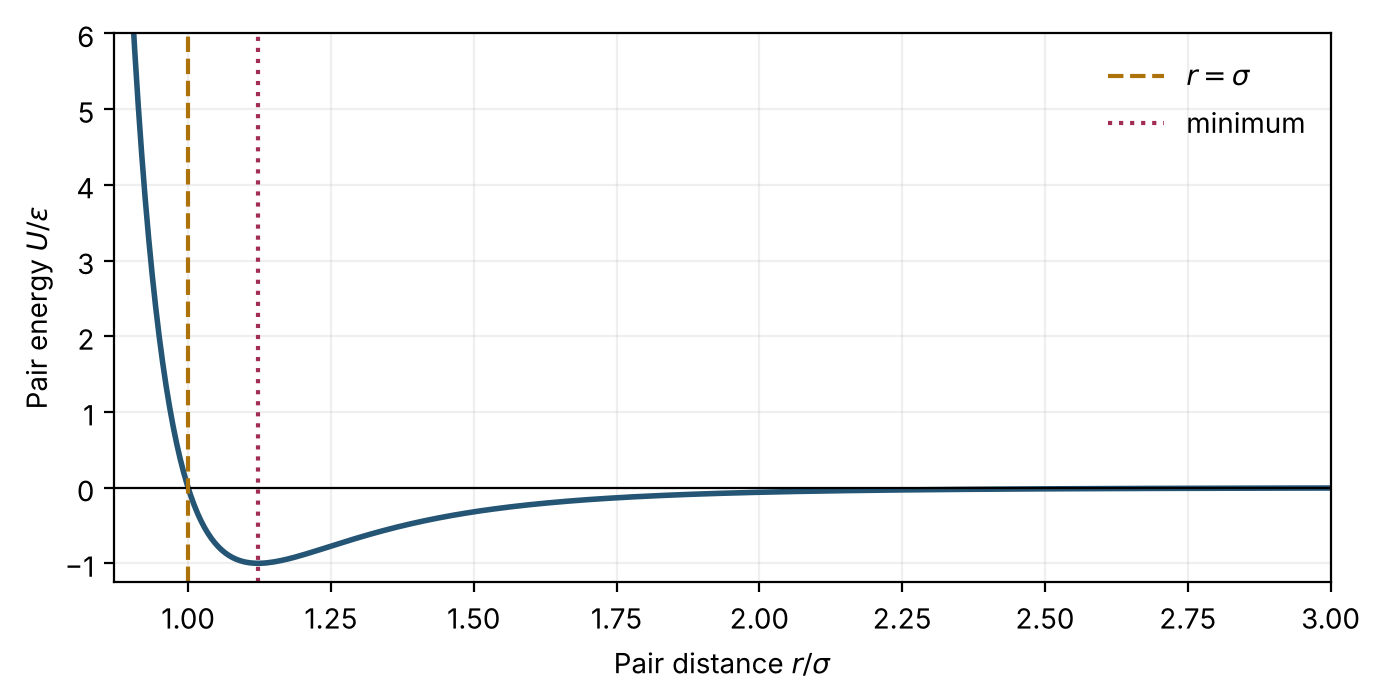

In [3]:
distance = np.linspace(0.87, 3.0, 350)  # Generate 350 evenly spaced points for interparticle distance r from 0.87 to 3.0
inverse_sixth = (1.0 / distance)**6  # Calculate the (sigma/r)^6 term for each distance value

# Compute the Lennard-Jones pair potential: U(r) = 4 * [(1/r)^12 - (1/r)^6]
pair_potential = 4.0 * (inverse_sixth**2 - inverse_sixth)

fig, ax = plt.subplots(figsize=(7, 3.6))  # Create a figure and axis object with dimensions 7x3.6 inches
ax.plot(distance, pair_potential, color='#245575', linewidth=2)  # Plot pair energy vs. distance using a blue-grey line
ax.axhline(0, color='black', linewidth=0.8)  # Draw a thin horizontal reference line at potential energy y = 0
ax.axvline(1.0, color='#ae720b', linestyle='--', label=r'$r=\sigma$')  # Draw a dashed vertical line at r = 1.0 where U(r) = 0
ax.axvline(2**(1/6), color='#a12c56', linestyle=':', label='minimum')  # Draw a dotted vertical line at r = 2^(1/6), the energy minimum
ax.set(  # Apply axis boundaries and LaTeX-formatted axis labels
    xlim=(0.87, 3.0),
    ylim=(-1.25, 6),
    xlabel=r'Pair distance $r/\sigma$',
    ylabel=r'Pair energy $U/\varepsilon$'
)
ax.legend(frameon=False)  # Render the legend without a surrounding border box
ax.grid(alpha=0.2)  # Enable a background grid with 20% opacity
fig.tight_layout()  # Automatically adjust subplots so labels fit neatly without overlapping
plt.show()  # Render and open the final plot window


### From energy to force

Force is the negative slope of potential energy. If $\mathbf d=\mathbf r_i-\mathbf r_j$ and $r=|\mathbf d|$, the force **on $i$ due to $j$** is

$$\mathbf F_{ij}=24\left(\frac{2}{r^{12}}-\frac{1}{r^6}\right)\frac{\mathbf d}{r^2}.$$

The reduced-unit constants are all one. At a short distance the coefficient is positive and the particles push apart; sufficiently far apart it is negative and they pull together. Newton's third law gives $\mathbf F_{ji}=-\mathbf F_{ij}$. We calculate each pair only once, then add its force to one particle and subtract it from the other.

**Check before continuing.** At $r=1$, the potential is zero, but is the force zero? Use the force formula: it is repulsive. Zero potential and zero force are different statements.


### Efficient computing E2: why the 12-6 potential is cheap to evaluate

The distance $r=\sqrt{d_x^2+d_y^2}$ requires a **square root**, which costs considerably more than an addition or a multiplication. A general power such as `r**-12` is more expensive still. The LJ 12-6 form lets us avoid both, because both exponents are **even**. Everything can be built from $r^2$:

$$\frac{1}{r^6}=\left(\frac{1}{r^2}\right)^3,\qquad \frac{1}{r^{12}}=\left(\frac{1}{r^6}\right)^2,\qquad \mathbf F_{ij}=24\left(\frac{2}{r^{12}}-\frac{1}{r^6}\right)\frac{1}{r^2}\,\mathbf d .$$

The force vector also needs only $1/r^2$: the unit vector $\mathbf d/r$ and the $1/r$ in $dU/dr$ combine into $\mathbf d/r^2$. Per pair the program therefore needs **one division and a few multiplications**, and never a square root. The cutoff test works the same way: compare $r^2$ with $r_c^2$ (computed once), not $r$ with $r_c$.

This convenience is a large part of why the exponent 12 became standard; $12 = 2\times6$. The physical short-range repulsion between atoms is closer to an exponential, as in the Buckingham potential $U=Ae^{-r/\rho}-C/r^6$, which needs a square root **and** an exponential for every pair.

The next cell computes the total LJ energy of 100 000 pair distances in two ways and times both. Timings depend on your computer and on what else it is doing, so compare the **ratio**, not the absolute numbers.

In [4]:
import time  # Built-in module with a high-resolution stopwatch, time.perf_counter()

demo_rng = np.random.default_rng(0)  # Separate generator so this demonstration does not affect anything else
squared_distances = demo_rng.uniform(0.8, 6.25, 100_000).tolist()  # 100 000 values of r^2 as plain Python floats


def energy_via_square_root(r2_values):  # Route 1: take the square root, then use general powers
    total = 0.0  # Accumulator for the total pair energy
    for r2 in r2_values:  # Visit every squared distance
        r = math.sqrt(r2)  # Expensive: a square root for every pair
        total += 4.0 * (r**-12 - r**-6)  # Expensive: two general (negative) powers
    return total  # Return the summed energy


def energy_via_r2(r2_values):  # Route 2: work with r^2 only
    total = 0.0  # Accumulator for the total pair energy
    for r2 in r2_values:  # Visit every squared distance
        inverse_r2 = 1.0 / r2  # One division
        inverse_r6 = inverse_r2 * inverse_r2 * inverse_r2  # Two multiplications give 1/r^6
        total += 4.0 * (inverse_r6 * inverse_r6 - inverse_r6)  # One more multiplication gives 1/r^12
    return total  # Return the summed energy


def best_time(function, argument, repeats=5):  # Run a function several times and keep the fastest timing
    best = float('inf')  # Start with an "infinitely slow" time
    for _ in range(repeats):  # Repeat to reduce the effect of background activity on the computer
        start = time.perf_counter()  # Start the stopwatch
        function(argument)  # Run the code being timed
        best = min(best, time.perf_counter() - start)  # Keep the shortest elapsed time
    return best  # Fastest run, in seconds


time_sqrt = best_time(energy_via_square_root, squared_distances)  # Time route 1
time_r2 = best_time(energy_via_r2, squared_distances)  # Time route 2
print(f'Square-root route: {1000 * time_sqrt:6.1f} ms')  # Report in milliseconds
print(f'r-squared route:   {1000 * time_r2:6.1f} ms')  # Report in milliseconds
print(f'Speed-up: {time_sqrt / time_r2:.1f} x')  # How many times faster the r^2 route is
same_answer = math.isclose(energy_via_square_root(squared_distances), energy_via_r2(squared_distances), rel_tol=1e-12)  # Same physics?
print('Same total energy (to 12 significant digits):', same_answer)  # Both routes must agree
assert same_answer  # Stop here if the two routes disagree

Square-root route:   12.6 ms
r-squared route:      5.3 ms
Speed-up: 2.4 x
Same total energy (to 12 significant digits): True


Both routes give the same answer, but the $r^2$ route is noticeably faster even in Python, where much of the time goes into running the loop itself. In compiled languages such as C or Fortran, where the loop costs very little, the advantage of avoiding square roots and general powers can be larger. Look for these ideas when you read `forces_and_potential` in Section 3.

## 2. The box and its periodic boundary

We place 16 particles on a $4\times4$ lattice in a **two-dimensional** square box. A particle leaving the right edge re-enters at the left edge; the same rule applies vertically. This is a computational tiling device, not a physical wall. The number density is $\rho^*=N/L^2=0.45$, so the box length is $L=\sqrt{N/0.45}$.

For a pair, we choose the nearest periodic copy. For instance, positions $x=0.2$ and $x=5.8$ in a box of length 6 are separated by $0.4$, not $5.6$. In code, `delta -= L * np.rint(delta / L)` applies this **minimum-image convention** to both coordinates. We include pairs only if $r<r_c=2.5\sigma$; here $r_c<L/2$, so that rule is consistent with the nearest-image calculation. At the cutoff we subtract the small value $U(r_c)$ from each included pair energy, making the potential energy continuous as a pair enters or leaves the interaction range. The force is set to zero beyond the cutoff and remains discontinuous at $r_c$. This is a teaching approximation whose effect we examine through the energy check.


In [5]:
grid_side = 4  # Set the number of grid points along each side of the square lattice
particle_count = grid_side**2  # Calculate the total particle count (N = 16)
number_density = 0.45  # Define the 2D particle number density (particles per unit area)
box_length = math.sqrt(particle_count / number_density)  # Compute simulation box side length L = sqrt(N / density)
grid_spacing = box_length / grid_side  # Compute physical spacing between adjacent grid cells

# Generate particle coordinates centered in each grid cell and convert to a (16, 2) NumPy float array
starting_positions = np.array([
    [(ix + 0.5) * grid_spacing, (iy + 0.5) * grid_spacing]
    for iy in range(grid_side) for ix in range(grid_side)
], dtype=float)

# Minimum-image example from the text: two particles at x = 0.2 and x = 5.8 in a box of length 6.0
first_point = np.array([0.2, 1.0])  # (x, y) of the first particle
second_point = np.array([5.8, 1.0])  # (x, y) of the second particle
delta_example = first_point - second_point  # Raw separation: x-component -5.6, y-component 0.0

# Apply minimum image convention: dr_nearest = dr - L * round(dr / L) to account for periodic boundary conditions
nearest_example = delta_example - 6.0 * np.rint(delta_example / 6.0)  # x-component becomes +0.4: the nearest copy is 0.4 away

print(f'N = {particle_count}; L = {box_length:.3f}; spacing = {grid_spacing:.3f}')  # Display particle count, box length, and grid spacing
print('Array shape:', starting_positions.shape)  # Print the shape dimensions of the positions array
print('First particle:', starting_positions[0])  # Print the (x, y) coordinates of the first particle
print('Raw separation:', delta_example, '-> minimum-image separation:', nearest_example)  # -5.6 becomes 0.4, as in the text


N = 16; L = 5.963; spacing = 1.491
Array shape: (16, 2)
First particle: [0.74535599 0.74535599]
Raw separation: [-5.6  0. ] -> minimum-image separation: [0.4 0. ]


The starting lattice prevents particles from overlapping. It is an artificial initial condition, not evidence of a crystalline phase. Velocities are random and the particles will move away from these initial sites.


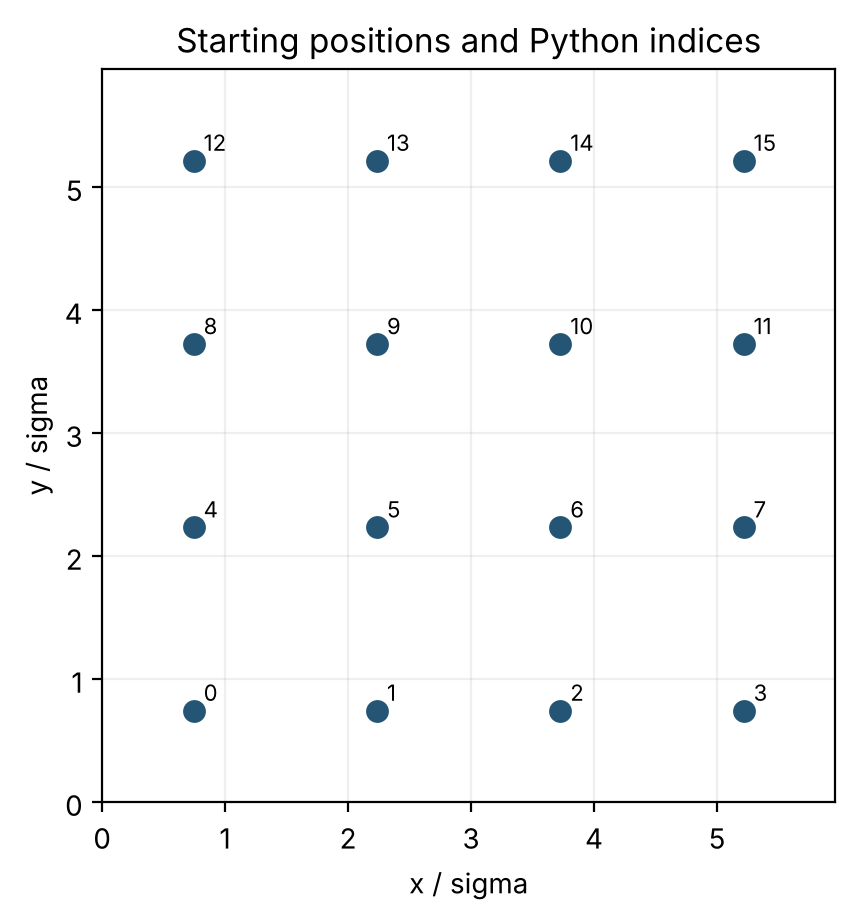

In [6]:
fig, ax = plt.subplots(figsize=(4.7, 4.7))  # Create a square figure and axis object with dimensions 4.7x4.7 inches
ax.scatter(starting_positions[:, 0], starting_positions[:, 1], s=85,  # Plot particle x (col 0) and y (col 1) coordinates with size 85
           color='#245575', edgecolor='white')  # Set point color to blue-grey with a white border
for index, (x, y) in enumerate(starting_positions):  # Loop through particle coordinates along with their index numbers
    ax.text(x + 0.08, y + 0.08, str(index), fontsize=8)  # Annotate each point with its array index, slightly offset (0.08 units)
ax.set(xlim=(0, box_length), ylim=(0, box_length), xlabel='x / sigma',  # Set axis range from 0 to box length and label x-axis
       ylabel='y / sigma', title='Starting positions and Python indices')  # Label y-axis and set the plot title
ax.set_aspect('equal')  # Lock a 1:1 aspect ratio so the square simulation box is rendered undistorted
ax.grid(alpha=0.2)  # Display a faint background grid with 20% opacity
fig.tight_layout()  # Adjust visual elements to fit neatly within the figure frame
plt.show()  # Render and display the plot window


### Efficient computing E3: why start from a lattice rather than random positions?

Scattering the particles at random looks simpler, but it is unsafe or expensive, for three reasons.

1. **Overlaps produce enormous forces.** Two random points can land arbitrarily close together. Because of the $r^{-12}$ term, a pair at $r=0.5$ has $U\approx1.6\times10^{4}$ and a force of about $3.9\times10^{5}$. With $\Delta t=0.004$, one velocity Verlet step would change the velocity by about 1600 and move the particle about 6 length units, farther than the whole box. The simulation would explode, or would need a much smaller time step, and therefore many more steps.
2. **Avoiding overlaps by trial and error costs time.** We can reject any random position that lands too close to a particle already placed and try again. The number of attempts grows rapidly with density, and above a certain density the procedure may never finish.
3. **A lattice costs almost nothing.** Placing $N$ particles on a grid takes exactly $N$ placements, always succeeds, and guarantees a comfortable closest-pair distance (here the grid spacing, about $1.49\sigma$). The price is an artificial starting arrangement, which the particles forget as they move (see the remark above).

The next two cells measure points 1 and 2.

In [7]:
def closest_pair_distance(points, length):  # Smallest minimum-image distance between any two particles
    smallest_squared = float('inf')  # Start with an "infinitely far" pair
    for i in range(len(points) - 1):  # Visit each distinct pair once, as in Section 3
        # Partner j > i, so each pair is examined exactly once
        for j in range(i + 1, len(points)):
            delta = points[i] - points[j]  # Separation vector
            delta -= length * np.rint(delta / length)  # Minimum-image convention
            smallest_squared = min(smallest_squared, float(np.dot(delta, delta)))  # Compare squared distances (no square root, see E2)
    return math.sqrt(smallest_squared)  # One square root at the very end


print(f'Lattice: closest pair distance = {closest_pair_distance(starting_positions, box_length):.3f}')  # Grid spacing, about 1.49

placement_rng = np.random.default_rng(1)  # Separate generator for the random placements
n_trials = 1000  # Number of random configurations to examine
closest_random = []  # List to collect the closest distance of each random configuration
for trial in range(n_trials):  # Generate and examine many random configurations
    random_positions = placement_rng.uniform(0.0, box_length, size=(particle_count, 2))  # 16 uniformly random points in the box
    closest_random.append(closest_pair_distance(random_positions, box_length))  # Record this configuration's closest pair
closest_random = np.array(closest_random)  # Convert to an array for convenient analysis

typical = float(np.median(closest_random))  # The middle value: half of the configurations are even worse
# Report the experiment's size and density
print(f'Random placement, {n_trials} trials of {particle_count} particles at density {number_density}:')
# The typical (median) closest distance in a random configuration
print(f'  median closest distance           = {typical:.3f}')
# Fraction of configurations with a dangerously close pair (r < 0.3)
print(f'  share with a pair closer than 0.3 = {np.mean(closest_random < 0.3):.0%}  (would stop forces_and_potential with an error)')
# Fraction with a pair closer than 0.8, where repulsion is already very strong
print(f'  share with a pair closer than 0.8 = {np.mean(closest_random < 0.8):.0%}')
print(f'  LJ pair energy at the median distance = {4 * (typical**-12 - typical**-6):.2e}')  # Compare with the well depth of -1
print(f'  LJ force at the median distance       = {24 * (2 * typical**-13 - typical**-7):.2e}')  # Compare with forces of order 1

Lattice: closest pair distance = 1.491


Random placement, 1000 trials of 16 particles at density 0.45:
  median closest distance           = 0.252
  share with a pair closer than 0.3 = 62%  (would stop forces_and_potential with an error)
  share with a pair closer than 0.8 = 100%
  LJ pair energy at the median distance = 6.08e+07
  LJ force at the median distance       = 2.90e+09


density 0.10: attempts [39, 42, 41]
density 0.20: attempts [42, 47, 49]
density 0.30: attempts [53, 62, 58]
density 0.45: attempts [84, 76, 78]
density 0.60: attempts [172, 201, 169]
density 0.70: attempts [307, 272, 475]
density 0.75: attempts [547, 583, 693]


density 0.80: attempts [11616, 1731, 2591]


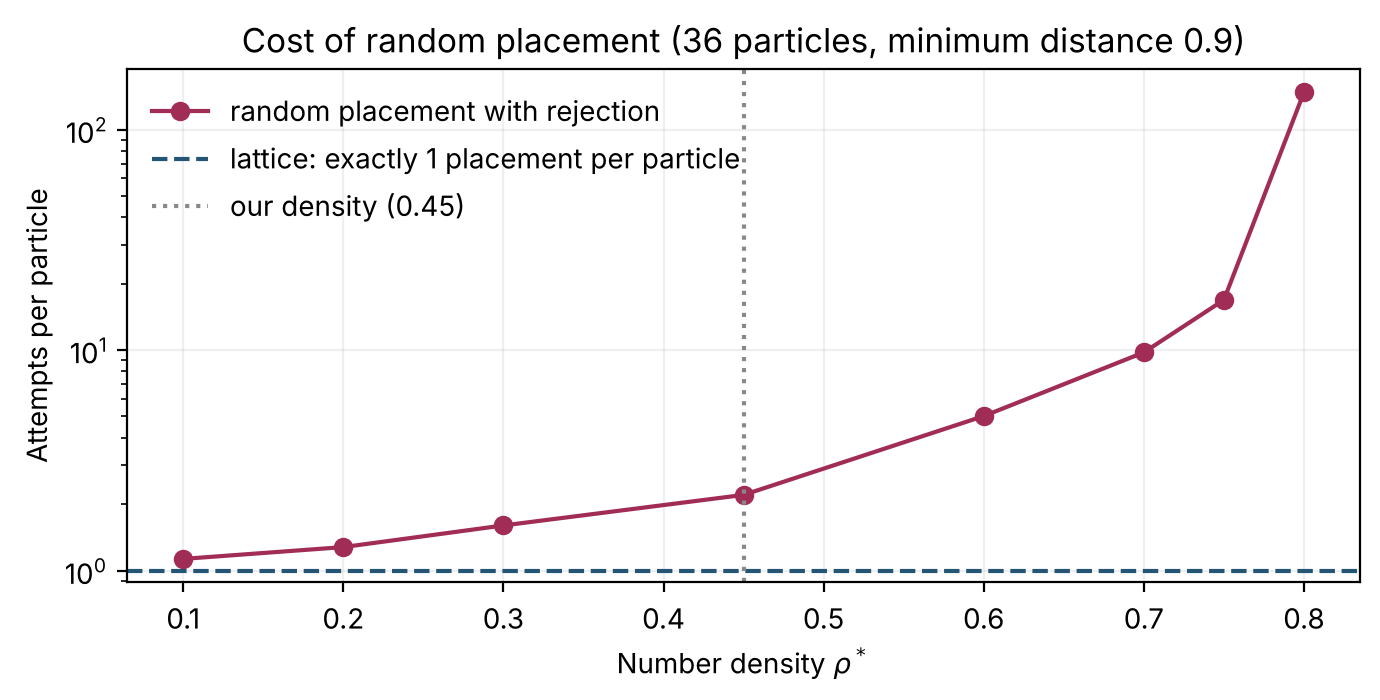

In [8]:
# Define a function that measures how hard it is to place particles at random without overlaps
def random_placement_attempts(n, density, minimum_distance=0.9, max_attempts=20_000, seed=0):
    # Place n particles at random, rejecting any candidate closer than minimum_distance to a placed particle.
    # Return the number of attempts needed, or None if we give up after max_attempts.
    rng = np.random.default_rng(seed)  # Reproducible random numbers
    length = math.sqrt(n / density)  # Box length for this density
    placed = []  # Positions accepted so far
    attempts = 0  # Counter of candidate positions tried
    while len(placed) < n:  # Keep going until all n particles are placed
        attempts += 1  # One more candidate
        if attempts > max_attempts:  # Safety valve: a while loop must be able to stop
            return None  # Give up
        candidate = rng.uniform(0.0, length, size=2)  # A random trial position
        too_close = False  # Assume the candidate is acceptable until proven otherwise
        for other in placed:  # Compare with every particle already placed
            delta = candidate - other  # Separation vector
            delta -= length * np.rint(delta / length)  # Minimum-image convention
            if np.dot(delta, delta) < minimum_distance**2:  # Squared-distance test (see E2)
                too_close = True  # Reject this candidate ...
                break  # ... and stop checking further particles
        if not too_close:  # Accept the candidate only if it overlaps nobody
            # Keep the accepted position
            placed.append(candidate)
    return attempts  # Total candidates tried


test_count = 36  # Particles per configuration in this experiment
test_densities = [0.1, 0.2, 0.3, 0.45, 0.6, 0.7, 0.75, 0.8]  # Increasing densities
attempts_per_particle = []  # Average attempts per particle at each density
for density in test_densities:  # Loop over densities
    results_here = [random_placement_attempts(test_count, density, seed=s) for s in range(3)]  # Three independent tries
    finished = [a for a in results_here if a is not None]  # Keep only the tries that succeeded
    attempts_per_particle.append(np.mean(finished) / test_count if finished else np.nan)  # nan if every try gave up
    print(f'density {density:4.2f}: attempts {results_here}')  # None means "gave up after 20 000 attempts"

fig, ax = plt.subplots(figsize=(7, 3.6))  # Figure for the comparison
ax.semilogy(test_densities, attempts_per_particle, 'o-', color='#a12c56', label='random placement with rejection')  # Log scale on y
ax.axhline(1.0, color='#245575', linestyle='--', label='lattice: exactly 1 placement per particle')  # Lattice cost
ax.axvline(number_density, color='#888888', linestyle=':', label=f'our density ({number_density})')  # Density used in this notebook
# Axis labels and title
ax.set(xlabel=r'Number density $\rho^*$', ylabel='Attempts per particle', title=f'Cost of random placement ({test_count} particles, minimum distance 0.9)')
ax.legend(frameon=False)  # Borderless legend
ax.grid(alpha=0.2)  # Faint grid
fig.tight_layout()  # Tidy layout
plt.show()  # Display the figure

At our density, more than half of the purely random placements contain a pair so close that `forces_and_potential` would stop with an error, and every one of them has a pair closer than $0.8\sigma$. Trial-and-error placement still works at this density, but needs more attempts than particles. As the density rises, the cost explodes and the procedure may never finish. The `while` loop above therefore has a **safety valve** (`max_attempts`): any loop whose end is not guaranteed should have one. Even a successful random configuration is not an equilibrium configuration, so it would still need time to relax, just like the lattice.

## 3. Calculate all pair forces

The outer loop visits particle indices `i = 0, ..., N-2`. The inner loop begins at `i + 1`, so it never compares a particle with itself or counts a pair twice. `displacement` is a two-component array, and `distance_squared` is its dot product with itself. Notice that the function never takes a square root: every quantity is built from `distance_squared` (Efficient computing E2).

The function returns **both** the force array and the total potential energy. The potential is accumulated once per interacting pair. A very small separation raises an error because the $r^{-12}$ interaction would otherwise produce an enormous number; this is a diagnostic, not an altered LJ potential. A second `if` skips pairs at or beyond the cutoff. For each included pair the code adds $U(r)-U(r_c)$, while retaining the LJ force shown above.


In [9]:
def forces_and_potential(positions, length):  # Define function to calculate net forces and shifted LJ potential for given positions and box length
    '''Return the force on each particle and the total shifted LJ pair potential energy.'''
    n = len(positions)  # Get the total number of particles n from the positions array
    forces = np.zeros_like(positions)  # Initialize an array of zeros with the same shape as positions to accumulate forces
    potential = 0.0  # Initialize accumulator for total system potential energy
    cutoff = 2.5  # Set the interaction cutoff radius r_c = 2.5
    cutoff_squared = cutoff**2  # Precompute r_c^2 so the cutoff test needs no square root (see E2)
    cutoff_inverse_sixth = (1.0 / cutoff)**6  # Compute (1/r_c)^6 for calculating the energy shift at cutoff
    # Precompute U(r_c) = 4 * [(1/r_c)^12 - (1/r_c)^6] to shift potential smoothly to zero at r_c
    potential_at_cutoff = 4.0 * (cutoff_inverse_sixth**2 - cutoff_inverse_sixth)

    for i in range(n - 1):  # Loop through particle index i from 0 to n - 2
        for j in range(i + 1, n):  # Loop through particle index j from i + 1 to n - 1 (unique pairs)
            displacement = positions[i] - positions[j]  # Compute displacement vector dr = r_i - r_j
            displacement -= length * np.rint(displacement / length)  # Apply minimum image convention across periodic boundaries
            distance_squared = np.dot(displacement, displacement)  # Compute squared interparticle distance r^2 = dr_x^2 + dr_y^2

            if distance_squared < 0.09:  # Check if particles overlap heavily (r < 0.3)
                raise ValueError('Particles are too close; inspect the setup.')  # Raise error to prevent unphysically large forces
            if distance_squared >= cutoff_squared:  # Check if particles are beyond the cutoff distance (r >= r_c)
                continue  # Skip pair calculations if outside interaction cutoff

            inverse_r2 = 1.0 / distance_squared  # Compute 1 / r^2
            inverse_r6 = inverse_r2**3  # Compute 1 / r^6 = (1 / r^2)^3
            inverse_r12 = inverse_r6**2  # Compute 1 / r^12 = (1 / r^6)^2
            # Accumulate shifted Lennard-Jones potential energy: U(r) - U(r_c)
            potential += 4.0 * (inverse_r12 - inverse_r6) - potential_at_cutoff

            # Compute force vector on particle i due to j: F_ij = (24/r^2) * [2*(1/r)^12 - (1/r)^6] * dr
            pair_force = (24.0 * (2.0 * inverse_r12 - inverse_r6) * inverse_r2 * displacement)
            forces[i] += pair_force  # Add pair force contribution to particle i
            forces[j] -= pair_force  # Apply equal and opposite force to particle j (Newton's Third Law)

    return forces, potential  # Return full array of forces per particle and total shifted potential energy

# Call function with initial grid positions and box size
initial_forces, initial_potential = forces_and_potential(
    starting_positions, box_length)
print('Initial potential energy:', round(initial_potential, 4))  # Output system potential energy rounded to 4 decimal places
print('Net force (x and y):', np.round(initial_forces.sum(axis=0), 12))  # Output sum of all particle forces (verifying total force is zero)


Initial potential energy: -10.9982
Net force (x and y): [0. 0.]


The nearly zero net force is a useful check of the equal-and-opposite updates. On the symmetric initial lattice, each individual net force is also small; this special symmetry does not persist as particles move.

For a direct test of the force calculation, take two particles separated by $r=1$ and place them in a box much wider than their separation. In reduced units, the force on the particle to the right should be $+24$ in the $x$ direction. The pair **energy** is not zero here: subtracting $U(r_c)$ changed its reference value. The following cell verifies the force without relying on the full 16-particle simulation.


In [10]:
two_positions = np.array([[2.0, 2.0], [1.0, 2.0]])  # Define coordinates for two particles separated by distance r = 1.0 along the x-axis
two_forces, two_potential = forces_and_potential(two_positions, length=10.0)  # Calculate forces and potential energy for the two-particle test configuration in a 10.0 x 10.0 box
print('Pair energy at r = 1:', two_potential)  # Print the shifted pair energy at r = 1: U(1) - U(r_c) = 0 - U(r_c), about +0.0163, not zero
print('Force on right particle:', two_forces[0])  # Print net force vector acting on particle 0 (at x = 2.0)
print('Force on left particle: ', two_forces[1])  # Print net force vector acting on particle 1 (at x = 1.0)
assert np.allclose(two_forces[0], [24.0, 0.0])  # Verify that the force on particle 0 matches theoretical LJ force [24.0, 0.0] at r = 1.0
assert np.allclose(two_forces.sum(axis=0), [0.0, 0.0])  # Verify Newton's Third Law (net system force sums to [0.0, 0.0])

cutoff_positions = np.array([[3.5, 2.0], [1.0, 2.0]])  # Define positions for two particles separated by exactly the cutoff distance (r = 2.5) along the x-axis
cutoff_forces, cutoff_potential = forces_and_potential(cutoff_positions, 10.0)  # Calculate forces and potential energy at the cutoff separation distance
print('Exactly at cutoff: energy =', cutoff_potential,  # Print potential energy and magnitude (norm) of total force vector at r = cutoff
      '; force norm =', np.linalg.norm(cutoff_forces))
assert cutoff_potential == 0.0  # Verify that potential energy is exactly zero at cutoff distance due to potential shifting
assert np.allclose(cutoff_forces, 0.0)  # Verify that forces drop to zero at or beyond the cutoff distance


Pair energy at r = 1: 0.016316891136000006
Force on right particle: [24.  0.]
Force on left particle:  [-24.   0.]
Exactly at cutoff: energy = 0.0 ; force norm = 0.0


## 4. Initial velocities and kinetic temperature

We draw the $x$ and $y$ velocity components from a normal random-number generator. The **seed** makes this starting draw reproducible. We then subtract the mean velocity, making the total momentum zero for equal masses, and rescale to an initial reduced kinetic temperature $T_0^*=0.90$.

With mass and $k_\mathrm B$ equal to one, $K=\tfrac12\sum_i(v_{ix}^2+v_{iy}^2)$. We remove two centre-of-mass velocity components, leaving $f=2N-2$ independent velocity degrees of freedom. The instantaneous kinetic-temperature estimate is therefore

$$T^*_{\mathrm{kin}}=\frac{2K}{2N-2}=\frac{K}{N-1}.$$

It may fluctuate during the run. This is an isolated, approximately constant-energy simulation with **no thermostat**; setting the initial value does not hold subsequent temperatures fixed. The temperature formula is for this *two-dimensional* setup, not a three-dimensional one.


In [11]:
def kinetic_energy(velocities):  # Define function to calculate total system kinetic energy (m = 1)
    '''Total kinetic energy when all particle masses are one: K = 0.5 * sum(v^2).'''
    # Sum v_x² + v_y² over all particles; float() turns the NumPy scalar into a plain Python number
    return 0.5 * float(np.sum(velocities**2))


def kinetic_temperature(velocities):  # Define function to calculate 2D kinetic temperature
    '''Two-dimensional kinetic temperature after removing centre-of-mass momentum.'''
    n = len(velocities)  # Get total particle count n
    degrees_of_freedom = 2 * n - 2  # Compute degrees of freedom (2D * N - 2 center-of-mass momentum constraints)
    return 2.0 * kinetic_energy(velocities) / degrees_of_freedom  # Calculate T* = 2 * K / N_dof via equipartition theory


def make_initial_velocities(seed, target_temperature, n):  # Define function to generate scaled initial particle velocities
    rng = np.random.default_rng(seed)  # Initialize NumPy random number generator with seed for reproducible results
    velocities = rng.normal(loc=0.0, scale=1.0, size=(n, 2))  # Sample 2D velocity components from standard normal distribution
    velocities -= velocities.mean(axis=0)  # Subtract mean velocity to ensure zero total center-of-mass momentum
    current_temperature = kinetic_temperature(velocities)  # Compute actual kinetic temperature of initial random distribution
    velocities *= math.sqrt(target_temperature / current_temperature)  # Rescale velocities to match target reduced temperature T*
    return velocities  # Return the properly initialized and scaled velocity array


random_seed = 2026  # Set random seed integer for simulation reproducibility
initial_temperature = 0.90  # Define target reduced initial temperature T* = 0.90
starting_velocities = make_initial_velocities(  # Call initialization function using target seed, temperature, and particle count
    random_seed, initial_temperature, particle_count
)
print('Initial K:', round(kinetic_energy(starting_velocities), 4))  # Calculate and display total kinetic energy rounded to 4 decimals
print('Initial T*:', round(kinetic_temperature(starting_velocities), 4))  # Calculate and display initial system temperature to verify target scaling
print('Mean velocity:', np.round(starting_velocities.mean(axis=0), 12))  # Output mean system velocity vector to verify zero net drift ([0, 0])

Initial K: 13.5
Initial T*: 0.9
Mean velocity: [-0. -0.]


## 5. Move the particles with velocity Verlet

For the first half-step in velocity and the full position step, Newton's law gives

$$\mathbf v_{n+1/2}=\mathbf v_n+\frac{\Delta t}{2}\mathbf F(\mathbf r_n),\qquad
\mathbf r_{n+1}=\mathbf r_n+\Delta t\,\mathbf v_{n+1/2}.$$

After recomputing the force at the new positions, finish the velocity step:

$$\mathbf v_{n+1}=\mathbf v_{n+1/2}+\frac{\Delta t}{2}\mathbf F(\mathbf r_{n+1}).$$

Mass is one in these equations. `positions %= box_length` wraps coordinates into the box; the unwrapped trajectory would require a separate counter. The `for` loop advances time. Each measurement is appended to a Python list; at the end we convert histories to arrays for plotting.

Notice that the half-step velocity $\mathbf v_{n+1/2}$ is an *intermediate* quantity. The box below explains why introducing it is not just a mathematical trick: it lets the program overwrite arrays instead of keeping extra ones.


### Efficient computing E4: the half-step velocity saves memory

Velocity Verlet can be written in several algebraically equivalent ways. Compare what each form must keep in memory during one step; each item is an array of $N\times d$ numbers.

| Form | Update | Arrays held during a step |
|:--|:--|:--|
| "Textbook" velocity Verlet | $\mathbf r_{n+1}=\mathbf r_n+\Delta t\,\mathbf v_n+\tfrac{\Delta t^2}{2}\mathbf F_n$; then $\mathbf v_{n+1}=\mathbf v_n+\tfrac{\Delta t}{2}\left(\mathbf F_n+\mathbf F_{n+1}\right)$ | $\mathbf r$, $\mathbf v$, $\mathbf F_n$, $\mathbf F_{n+1}$: **four** |
| Half-step ("kick–drift–kick") form used here | equations above | $\mathbf r$, $\mathbf v$, $\mathbf F$: **three** |

In the textbook form, the last line needs the old **and** the new forces at the same time. In the half-step form, $\mathbf F_n$ is used up in the first half-kick, so the new forces can **overwrite** it. Likewise $\mathbf v_{n+1/2}$ can overwrite $\mathbf v_n$, which is never needed again. (Substitute the first half-kick into the position update to check that both forms produce the same positions and velocities.) Verlet's original 1967 form, $\mathbf r_{n+1}=2\mathbf r_n-\mathbf r_{n-1}+\Delta t^2\mathbf F_n$, also holds three arrays, but it carries the previous positions instead of velocities.

For 16 particles the saving is irrelevant. Research simulations, however, follow millions to billions of atoms, often on graphics processors (GPUs) with limited memory, where one extra array can decide whether a simulation fits at all.

Python realises this saving through **in-place operations**. `velocities += x` changes the numbers inside the existing array, while `velocities = velocities + x` builds a new array and then moves the name `velocities` to it. The cells below (1) put numbers on the memory cost, (2) show the difference between the two kinds of assignment, and (3) check that an in-place step gives exactly the same numbers as a step that creates new arrays.

In [12]:
bytes_per_number = np.dtype(np.float64).itemsize  # A float64 number occupies 8 bytes
print('One (16, 2) position array in this notebook:', starting_positions.nbytes, 'bytes')  # 16 x 2 x 8 = 256 bytes

cases = [('This notebook, 2D', 16, 2), ('1 million atoms, 3D', 10**6, 3), ('1 billion atoms, 3D', 10**9, 3)]  # (label, N, dimensions)
print(f"\n{'System':22s} {'one array':>12s} {'3 arrays':>12s} {'4 arrays':>12s}")  # Table header
for label, n_atoms, dims in cases:  # One row per system size
    one_array_GB = n_atoms * dims * bytes_per_number / 1e9  # Size of one N x d array in gigabytes
    # One table row: memory for 1, 3 and 4 arrays of this size
    print(f'{label:22s} {one_array_GB:9.2e} GB {3 * one_array_GB:9.2e} GB {4 * one_array_GB:9.2e} GB')

# The same reasoning applies to what we store over time
every_step_here = (10_000 + 1) * particle_count * 2 * bytes_per_number  # Positions saved at every one of 10 000 steps, 16 particles
every_step_big = (10**6 + 1) * 10**6 * 3 * bytes_per_number  # Positions saved at every one of 10^6 steps, 10^6 atoms in 3D
# Compare storing every frame here with storing every frame of a large simulation
print(f'\nSaving positions at every step: {every_step_here / 1e6:.1f} MB here, but {every_step_big / 1e12:.0f} TB for 10^6 atoms over 10^6 steps.')
# The design choice this explains
print('That is why run_md stores scalar histories every step but positions only three times.')

One (16, 2) position array in this notebook: 256 bytes

System                    one array     3 arrays     4 arrays
This notebook, 2D       2.56e-07 GB  7.68e-07 GB  1.02e-06 GB
1 million atoms, 3D     2.40e-02 GB  7.20e-02 GB  9.60e-02 GB
1 billion atoms, 3D     2.40e+01 GB  7.20e+01 GB  9.60e+01 GB

Saving positions at every step: 2.6 MB here, but 24 TB for 10^6 atoms over 10^6 steps.
That is why run_md stores scalar histories every step but positions only three times.


In [13]:
demo = np.zeros(3)  # A small array
same_array = demo  # A second NAME for the SAME array (no copy is made)

demo += 1.0  # In place: the numbers inside the existing array change
# In-place update: both names still refer to the same, changed array
print('After demo += 1:      same object?', demo is same_array, '| same_array =', same_array)

demo = demo + 1.0  # New array: demo + 1.0 is built first, then the name 'demo' moves to it
# New array: 'demo' now names a different array, while same_array keeps the old values
print('After demo = demo + 1: same object?', demo is same_array, '| same_array =', same_array, '| demo =', demo)

After demo += 1:      same object? True | same_array = [1. 1. 1.]
After demo = demo + 1: same object? False | same_array = [1. 1. 1.] | demo = [2. 2. 2.]


In-place changes are visible through **every** name that refers to the array. This is efficient, but it has a consequence: `run_md` must start from `starting_positions.copy()`, or the in-place updates would overwrite the global starting lattice, and the next run would begin where the previous one ended. For the same reason, snapshots must be stored with `.copy()`; otherwise every "snapshot" would be the same, constantly changing array.

In [14]:
def step_with_new_arrays(positions, velocities, forces, dt):  # Straightforward translation: every line creates a new array
    halfway_velocity = velocities + 0.5 * dt * forces  # New array for v(t + dt/2)
    new_positions = (positions + dt * halfway_velocity) % box_length  # New array for r(t + dt)
    new_forces, _ = forces_and_potential(new_positions, box_length)  # New array for F(t + dt), while the old forces still exist
    new_velocities = halfway_velocity + 0.5 * dt * new_forces  # New array for v(t + dt)
    return new_positions, new_velocities, new_forces  # Five N x 2 arrays were alive at the end of this step


def step_in_place(positions, velocities, forces, dt):  # Memory-saving version: overwrite what is no longer needed
    velocities += 0.5 * dt * forces  # The velocity array now holds v(t + dt/2); v(t) is gone
    positions += dt * velocities  # The position array now holds r(t + dt)
    positions %= box_length  # Wrap into the box, in place
    forces, _ = forces_and_potential(positions, box_length)  # F(t) is no longer needed, so the name moves to F(t + dt)
    velocities += 0.5 * dt * forces  # The velocity array now holds v(t + dt)
    return positions, velocities, forces  # Three N x 2 arrays carry the state


# Give each version its own copies, because step_in_place modifies the arrays it receives
result_new = step_with_new_arrays(starting_positions.copy(), starting_velocities.copy(), initial_forces.copy(), 0.004)
# The in-place version, started from identical copies
result_in_place = step_in_place(starting_positions.copy(), starting_velocities.copy(), initial_forces.copy(), 0.004)
for name, a, b in zip(('positions', 'velocities', 'forces'), result_new, result_in_place):  # Compare the three outputs pairwise
    # Report whether the two versions give bit-for-bit identical results
    print(f'{name:10s} identical to the last bit: {np.array_equal(a, b)}')
    assert np.array_equal(a, b)  # Same arithmetic in the same order, so the results must match exactly

positions  identical to the last bit: True
velocities identical to the last bit: True
forces     identical to the last bit: True


The two versions do the same arithmetic in the same order, so their results agree **bit for bit**. Only the memory use differs. (In Python, `forces_and_potential` still builds its result as a new array, so old and new forces coexist for a moment inside the call. Compiled MD programs write the new forces directly into the existing array; the half-step form of the algorithm is what makes that possible.)

`run_md` below uses the in-place step. It also shows two everyday efficiency habits:

* **Compute once, reuse.** The kinetic energy is computed once per step and reused for the temperature, instead of calling `kinetic_temperature`, which would compute $K$ a second time.
* **Move loop-invariant work out of the loop.** The number of degrees of freedom, $2N-2$, never changes, so it is computed once before the loop rather than 10 000 times inside it.

Finally, `run_md` has a new argument, `force_function`. Functions are values in Python, so a different force routine can be passed in later (Section 6) without rewriting `run_md`.

In [15]:
# Define the simulation driver; force_function lets us swap in a faster force routine later
def run_md(seed=2026, time_step=0.004, n_steps=10000, force_function=forces_and_potential):
    '''Run a small 2D LJ simulation; return a dictionary of histories.'''
    positions = starting_positions.copy()  # Private copy: the in-place updates below must not alter the global starting lattice (E4)
    velocities = make_initial_velocities(seed, initial_temperature,  # Fresh, scaled initial velocities for this seed
                                         particle_count)
    forces, potential = force_function(positions, box_length)  # Initial forces F(0) and potential energy U(0)
    degrees_of_freedom = 2 * particle_count - 2  # Loop-invariant: computed once here, not once per step (E4)
    kinetic = kinetic_energy(velocities)  # Initial kinetic energy K(0)

    times = [0.0]  # Time history, starting at t = 0
    kinetic_history = [kinetic]  # Kinetic-energy history
    potential_history = [potential]  # Potential-energy history
    temperature_history = [2.0 * kinetic / degrees_of_freedom]  # Kinetic-temperature history, T* = 2K / (2N - 2)
    snapshots = {0: positions.copy()}  # Saved positions, keyed by step number

    for step in range(1, n_steps + 1):  # Advance the simulation one time step at a time
        velocities += 0.5 * time_step * forces  # First half-kick, in place: the array now holds v(t + dt/2)
        positions += time_step * velocities  # Drift, in place: r(t + dt)
        positions %= box_length  # Wrap coordinates back into the periodic box, in place
        forces, potential = force_function(positions, box_length)  # New forces F(t + dt) replace F(t), which is no longer needed
        velocities += 0.5 * time_step * forces  # Second half-kick, in place: v(t + dt)

        kinetic = kinetic_energy(velocities)  # Compute K once per step ...
        times.append(step * time_step)  # Record elapsed reduced time
        kinetic_history.append(kinetic)  # Record kinetic energy
        potential_history.append(potential)  # Record potential energy
        temperature_history.append(2.0 * kinetic / degrees_of_freedom)  # ... and reuse it for T* (same formula as kinetic_temperature)

        if step in (n_steps // 2, n_steps):  # Midpoint or final step
            snapshots[step] = positions.copy()  # .copy() is essential: 'positions' is modified in place at every step (E4)

    kinetic = np.array(kinetic_history)  # Convert histories to NumPy arrays for arithmetic and plotting
    # Same conversion for the potential-energy history
    potential = np.array(potential_history)
    return {  # Named collection of results
        'time': np.array(times),
        'kinetic': kinetic,
        'potential': potential,
        'total': kinetic + potential,
        'temperature': np.array(temperature_history),
        'snapshots': snapshots,
        'seed': seed,
        'time_step': time_step,
        'n_steps': n_steps,
    }

start = time.perf_counter()  # Start the stopwatch
results = run_md(n_steps=10000)  # Run the simulation for 10,000 steps and store the output dictionary in results
baseline_seconds = time.perf_counter() - start  # Elapsed run time, used again in Section 6
print('Recorded samples:', len(results['time']))  # 10,001 samples including the initial state at t = 0
print('Initial E*:', round(results['total'][0], 4))  # Initial total energy (K + U)
print('Final E*:  ', round(results['total'][-1], 4))  # Final total energy, to compare with the initial value
print(f'Run time: {baseline_seconds:.1f} s')  # How long the 10,000 steps took

Recorded samples: 10001
Initial E*: 2.5018
Final E*:   2.495
Run time: 5.2 s


## 6. Where does the time go? Measuring and speeding up the code

The run above took several seconds for only 16 particles. Before changing any code to make it faster, **measure** where the time is spent. Programmers call this *profiling*. Intuition is unreliable here, and the arithmetic of speed-ups is unforgiving: if a part of the program takes 5% of the run time, making it infinitely fast saves at most 5%.

### Efficient computing E5: measure first, then optimise the part that matters

The next cell uses the new `force_function` argument in a neat way. It passes `run_md` a small **wrapper** function that calls the real force routine but also adds the time spent inside it to a running total. `run_md` itself is not changed at all. The running total is kept in a dictionary, because a function may change the contents of a dictionary defined outside it.

In [16]:
force_timer = {'calls': 0, 'seconds': 0.0}  # Running totals, updated by the wrapper below


def timed_forces(positions, length):  # Same inputs and outputs as forces_and_potential ...
    start = time.perf_counter()  # ... but it also starts a stopwatch,
    result = forces_and_potential(positions, length)  # calls the real force routine,
    force_timer['seconds'] += time.perf_counter() - start  # adds the elapsed time to the running total,
    force_timer['calls'] += 1  # counts the call,
    return result  # and passes the result on unchanged


profile_steps = 1000  # A short run is enough to see the proportions
start = time.perf_counter()  # Stopwatch for the whole run
run_md(n_steps=profile_steps, force_function=timed_forces)  # Ordinary run, with the timing wrapper plugged in
total_seconds = time.perf_counter() - start  # Elapsed time for the whole run

# Total run time
print(f"Whole run of {profile_steps} steps:              {total_seconds:.2f} s")
# Time spent inside the force routine, and how many calls it made
print(f"Inside the force routine ({force_timer['calls']} calls): {force_timer['seconds']:.2f} s")
# The force routine's share of the run time
print(f"Share of the run time spent computing forces: {force_timer['seconds'] / total_seconds:.0%}")

Whole run of 1000 steps:              0.54 s
Inside the force routine (1001 calls): 0.53 s
Share of the run time spent computing forces: 98%


Practically all the time goes into the force calculation, so that is the only place worth optimising. But *why* is it slow? It visits only 120 pairs per call.

The answer is a property of NumPy that surprises many programmers: **NumPy is fast for large arrays and slow for tiny ones.** Every NumPy function call (`np.rint`, `np.dot`, even `+` between arrays) first checks types and shapes and sets up a loop. For an array of a million numbers this fixed overhead is negligible. For our two-component `displacement` array, the overhead *is* the cost, and we pay it several times for every pair. Plain Python numbers (`float`) carry much less overhead. The next cell measures the difference for single operations.

In [17]:
import timeit  # Built-in module for timing small snippets of code many times

d = np.array([0.7, -1.2])  # A two-component NumPy array, like 'displacement' in the force loop
dx, dy = 0.7, -1.2  # The same two numbers as plain Python floats
n_calls = 200_000  # Repeat each snippet many times so the timing is measurable

timings = {  # Time per call, in nanoseconds (1 ns = 1e-9 s)
    'np.dot(d, d)': timeit.timeit(lambda: np.dot(d, d), number=n_calls) / n_calls * 1e9,
    'dx*dx + dy*dy': timeit.timeit(lambda: dx * dx + dy * dy, number=n_calls) / n_calls * 1e9,
    'np.rint(d / 5.963)': timeit.timeit(lambda: np.rint(d / 5.963), number=n_calls) / n_calls * 1e9,
    'round(dx / 5.963), round(dy / 5.963)': timeit.timeit(lambda: (round(dx / 5.963), round(dy / 5.963)), number=n_calls) / n_calls * 1e9,
}
for snippet, nanoseconds in timings.items():  # Print a small table
    # One table row: snippet and its time per call
    print(f'{snippet:40s} {nanoseconds:7.0f} ns per call')

np.dot(d, d)                                 495 ns per call
dx*dx + dy*dy                                 45 ns per call
np.rint(d / 5.963)                           805 ns per call
round(dx / 5.963), round(dy / 5.963)         138 ns per call


The remedy needs no new ideas. Keep the same double loop, but convert the coordinates to plain Python lists **once per call**, work with separate `dx` and `dy` floats inside the loop, and convert the forces back to a NumPy array **once** at the end. The physics, the minimum-image rule, the cutoff and the safety check are unchanged. Two small extra habits appear: particle $i$'s coordinates are looked up once per outer iteration rather than once per pair, and Python's built-in `round`, which (like `np.rint`) rounds exact halves to the nearest even number, replaces `np.rint`.

In [18]:
# Define a faster force routine with the same inputs and outputs as forces_and_potential
def forces_and_potential_fast(positions, length):
    '''Same physics as forces_and_potential, using plain Python floats inside the pair loop.'''
    n = len(positions)  # Number of particles
    x = positions[:, 0].tolist()  # x-coordinates as a list of plain Python floats (one conversion per call)
    y = positions[:, 1].tolist()  # y-coordinates as a list of plain Python floats
    force_x = [0.0] * n  # Accumulators for the x-components of the net forces
    force_y = [0.0] * n  # Accumulators for the y-components of the net forces
    potential = 0.0  # Accumulator for the total shifted potential energy
    cutoff_squared = 2.5**2  # r_c^2, so the cutoff test needs no square root (E2)
    cutoff_inverse_sixth = (1.0 / 2.5)**6  # (1/r_c)^6 for the energy shift
    potential_at_cutoff = 4.0 * (cutoff_inverse_sixth**2 - cutoff_inverse_sixth)  # U(r_c)

    for i in range(n - 1):  # Particle i = 0, ..., n-2
        x_i = x[i]  # Look up particle i once per outer iteration, not once per pair
        # Same for the y-coordinate
        y_i = y[i]
        for j in range(i + 1, n):  # Partner j > i: each pair exactly once
            dx = x_i - x[j]  # Separation components as plain floats
            # y-component of the separation
            dy = y_i - y[j]
            dx -= length * round(dx / length)  # Minimum-image convention, x
            dy -= length * round(dy / length)  # Minimum-image convention, y
            distance_squared = dx * dx + dy * dy  # r^2 without NumPy overhead

            if distance_squared < 0.09:  # Same safety check as before (r < 0.3)
                # Stop with a clear message instead of producing huge forces
                raise ValueError('Particles are too close; inspect the setup.')
            if distance_squared >= cutoff_squared:  # Pair beyond the cutoff: skip it
                # Skip to the next partner j
                continue

            inverse_r2 = 1.0 / distance_squared  # 1/r^2
            inverse_r6 = inverse_r2**3  # 1/r^6
            inverse_r12 = inverse_r6**2  # 1/r^12
            potential += 4.0 * (inverse_r12 - inverse_r6) - potential_at_cutoff  # Shifted pair energy

            coefficient = 24.0 * (2.0 * inverse_r12 - inverse_r6) * inverse_r2  # Scalar factor multiplying (dx, dy)
            force_x[i] += coefficient * dx  # Force on i due to j
            # y-component of the force on i
            force_y[i] += coefficient * dy
            force_x[j] -= coefficient * dx  # Equal and opposite force on j (Newton's third law)
            # Equal and opposite y-component on j
            force_y[j] -= coefficient * dy

    return np.column_stack((force_x, force_y)), potential  # Back to an (n, 2) NumPy array, once, at the end

In [19]:
# 1. Repeat the hand-checkable tests from Section 3
two_forces_fast, _ = forces_and_potential_fast(two_positions, 10.0)  # Two particles at r = 1
cutoff_forces_fast, cutoff_potential_fast = forces_and_potential_fast(cutoff_positions, 10.0)  # Two particles at r = r_c
assert np.allclose(two_forces_fast[0], [24.0, 0.0])  # Expected repulsive force
assert cutoff_potential_fast == 0.0 and np.allclose(cutoff_forces_fast, 0.0)  # Nothing at the cutoff

# 2. Compare both routines on several disordered configurations
check_rng = np.random.default_rng(7)  # Separate generator for the test configurations
largest_difference = 0.0  # Largest force difference seen so far
for trial in range(5):  # Five random distortions of the lattice
    # Shift every particle randomly by up to ±0.4 and wrap back into the box
    test_configuration = (starting_positions + check_rng.uniform(-0.4, 0.4, size=starting_positions.shape)) % box_length
    reference_forces, reference_potential = forces_and_potential(test_configuration, box_length)  # Trusted version
    fast_forces, fast_potential = forces_and_potential_fast(test_configuration, box_length)  # New version
    # Both routines must agree on forces and potential, to round-off
    assert np.allclose(reference_forces, fast_forces) and math.isclose(reference_potential, fast_potential)
    # Track the largest force difference seen across the trials
    largest_difference = max(largest_difference, float(np.max(np.abs(reference_forces - fast_forces))))
print(f'Largest force difference between the two routines: {largest_difference:.1e}')  # Round-off level for forces of this size

# 3. Time both routines on the same configuration
time_reference = best_time(lambda p: forces_and_potential(p, box_length), test_configuration, repeats=200)
# Time the fast version on the same configuration
time_fast = best_time(lambda p: forces_and_potential_fast(p, box_length), test_configuration, repeats=200)
# Time per call of the original routine, in microseconds
print(f'forces_and_potential:      {1e6 * time_reference:7.0f} microseconds per call')
# Time per call of the fast routine
print(f'forces_and_potential_fast: {1e6 * time_fast:7.0f} microseconds per call')
# How many times faster the new routine is
print(f'Speed-up: {time_reference / time_fast:.1f} x')

Largest force difference between the two routines: 2.0e-13
forces_and_potential:          438 microseconds per call
forces_and_potential_fast:      51 microseconds per call
Speed-up: 8.6 x


### Efficient computing E6: faster code must be checked again, and it may round differently

The two routines agree to within about $10^{-13}$, the level of floating-point round-off for forces of this size, but not to the last bit. Changing how a sum is computed can change its final rounded digit. For example, `np.dot` may combine a multiplication and an addition into one rounding step, whereas `dx*dx + dy*dy` rounds twice. Such differences are harmless in a single force evaluation. But MD trajectories are **chaotic**: a tiny difference grows roughly exponentially with time, just like the famous "butterfly effect" in weather prediction.

The next cell runs the full simulation with the fast routine and compares it with `results` from Section 5.

Run time: 5.2 s with forces_and_potential, 0.8 s with forces_and_potential_fast
Later-half mean T*: 1.258 (reference) vs 1.247 (fast)


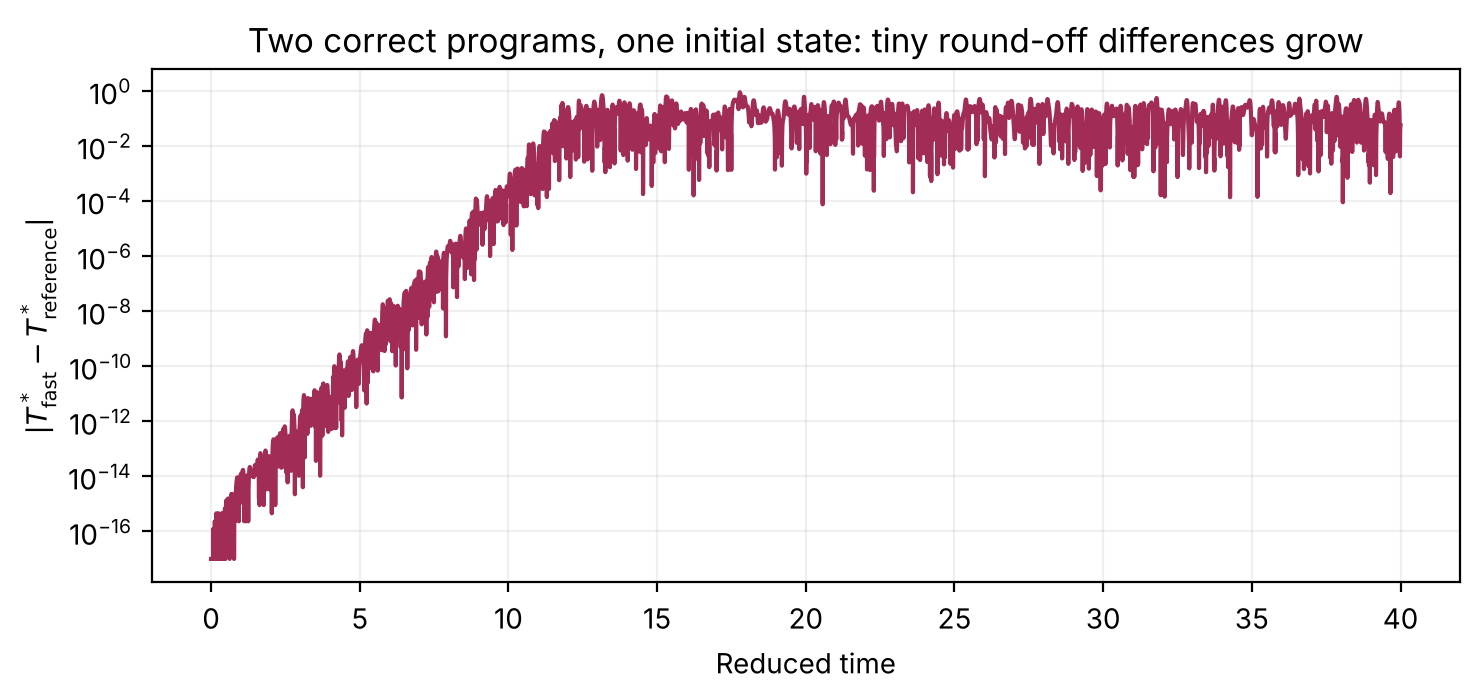

In [20]:
start = time.perf_counter()  # Stopwatch for the fast run
results_fast = run_md(n_steps=10000, force_function=forces_and_potential_fast)  # Same seed and settings, new force routine
fast_seconds = time.perf_counter() - start  # Elapsed time
# Compare the wall-clock times of the two full runs
print(f'Run time: {baseline_seconds:.1f} s with forces_and_potential, {fast_seconds:.1f} s with forces_and_potential_fast')

temperature_gap = np.abs(results_fast['temperature'] - results['temperature'])  # Step-by-step difference between the two runs
half = len(results['time']) // 2  # Start of the later-half window used in Section 8
# The later-half averages agree even though the step-by-step values diverge
print(f"Later-half mean T*: {np.mean(results['temperature'][half:]):.3f} (reference) vs {np.mean(results_fast['temperature'][half:]):.3f} (fast)")

fig, ax = plt.subplots(figsize=(7.5, 3.6))  # Figure for the divergence
ax.semilogy(results['time'], temperature_gap + 1e-17, color='#a12c56')  # Log scale; the tiny offset avoids log(0) at t = 0
# Axis labels and title
ax.set(xlabel='Reduced time', ylabel=r'$|T^*_{\mathrm{fast}}-T^*_{\mathrm{reference}}|$',
       title='Two correct programs, one initial state: tiny round-off differences grow')
ax.grid(alpha=0.2)  # Faint grid
fig.tight_layout()  # Tidy layout
plt.show()  # Display the figure

The difference starts at the round-off level, grows by many orders of magnitude, and then saturates once the two trajectories are completely unrelated. Yet the two later-half mean temperatures differ only in the second decimal place, far less than the step-to-step fluctuations of $T^*$ (sample SD about 0.13, Section 8). Changing the seed (Section 10) produces differences of a similar size. A careful comparison would attach uncertainties to these means by using several independent runs. Two lessons follow:

* **Verify optimised code against the trusted version**, at the level where agreement is expected: individual force calls to round-off, and long-run *averages* to within statistical noise. Do not expect two different but correct programs to produce identical long trajectories.
* **Bit-for-bit reproducibility** (Section 9) requires the same code, the same order of operations and, strictly, the same software and hardware. That is a property of the *program*, not of the physics.

From here on we use the fast routine for the remaining runs.

### Efficient computing E7: how the cost grows with the number of particles

The double loop visits $N(N-1)/2$ pairs, so doubling $N$ roughly **quadruples** the work. Computer scientists write this as $O(N^2)$ ("order $N$ squared"). The next cell measures it.

N =   16:     120 pairs,    0.051 ms per force call
N =   36:     630 pairs,    0.197 ms per force call
N =   64:    2016 pairs,    0.560 ms per force call
N =  144:   10296 pairs,    2.582 ms per force call


N =  256:   32640 pairs,    7.820 ms per force call


N =  576:  165600 pairs,   40.548 ms per force call
In the N = 576 system only 1.4% of the pairs checked are inside the cutoff.


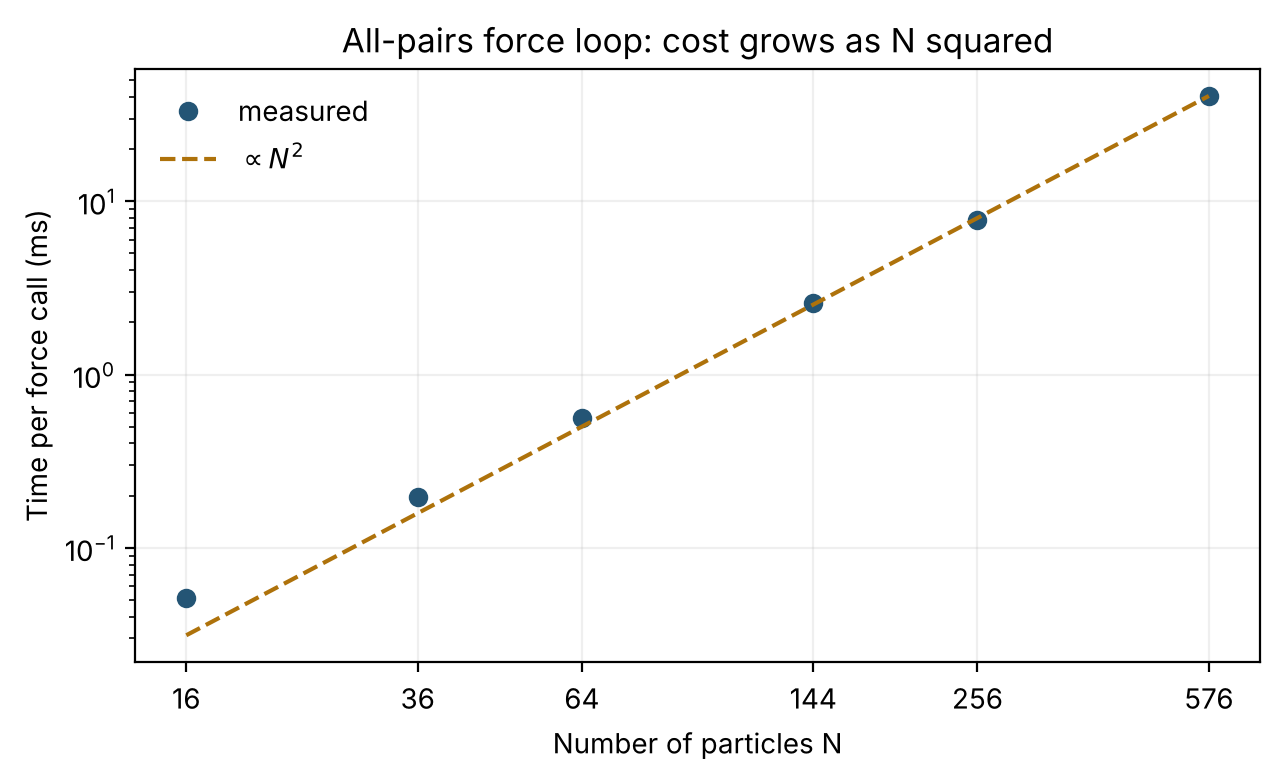

Extrapolated time for ONE force call with N = 10 000: about 12 s


In [21]:
grid_sides = [4, 6, 8, 12, 16, 24]  # Lattices of 16 to 576 particles
size_rng = np.random.default_rng(11)  # Separate generator for small random displacements
counts, seconds_per_call = [], []  # Collect N and the time per force call
for side in grid_sides:  # One measurement per system size
    n = side**2  # Number of particles
    length = math.sqrt(n / number_density)  # Box length at the same density as before
    spacing = length / side  # Lattice spacing
    # Build a side × side square lattice, one (x, y) point per particle
    lattice = np.array([[(ix + 0.5) * spacing, (iy + 0.5) * spacing] for iy in range(side) for ix in range(side)])
    configuration = (lattice + size_rng.uniform(-0.2, 0.2, size=lattice.shape)) % length  # Slightly disordered lattice
    repeats = max(5, 4000 // n)  # Fewer repeats for the slow, large systems; the fastest repeat is kept
    # Record the system size
    counts.append(n)
    # Record the fastest time per force call for this size
    seconds_per_call.append(best_time(lambda p: forces_and_potential_fast(p, length), configuration, repeats=repeats))
    # Report the number of pairs and the time per call
    print(f'N = {n:4d}: {n * (n - 1) // 2:7d} pairs, {1000 * seconds_per_call[-1]:8.3f} ms per force call')

# How many of the pairs checked in the largest system actually interact?
separations = configuration[:, None, :] - configuration[None, :, :]  # All pair separations at once (an advanced NumPy trick)
separations -= length * np.rint(separations / length)  # Minimum-image convention
pair_r2 = np.sum(separations**2, axis=-1)[np.triu_indices(counts[-1], k=1)]  # r^2 of each distinct pair
# Most of the N² work is spent on pairs beyond the cutoff
print(f'In the N = {counts[-1]} system only {np.mean(pair_r2 < 2.5**2):.1%} of the pairs checked are inside the cutoff.')

counts, seconds_per_call = np.array(counts), np.array(seconds_per_call)  # Arrays for arithmetic and plotting
fig, ax = plt.subplots(figsize=(6.5, 4.0))  # Figure for the scaling
ax.loglog(counts, 1000 * seconds_per_call, 'o', color='#245575', label='measured')  # Log-log axes
ax.loglog(counts, 1000 * seconds_per_call[-1] * (counts / counts[-1])**2, '--', color='#ae720b', label=r'$\propto N^2$')  # Slope-2 guide
# Axis labels and title
ax.set(xlabel='Number of particles N', ylabel='Time per force call (ms)', title='All-pairs force loop: cost grows as N squared')
ax.set_xticks(counts, [str(n) for n in counts])  # Label the measured sizes directly
ax.xaxis.set_minor_locator(plt.NullLocator())  # Remove crowded minor tick labels
ax.legend(frameon=False)  # Borderless legend
ax.grid(alpha=0.2)  # Faint grid
fig.tight_layout()  # Tidy layout
plt.show()  # Display the figure

estimate_10k = seconds_per_call[-1] * (10_000 / counts[-1])**2  # Extrapolate with the N^2 law
# Report the extrapolated cost
print(f'Extrapolated time for ONE force call with N = 10 000: about {estimate_10k:.0f} s')

On a log–log plot a power law appears as a straight line, and the measured points follow the slope-2 guide. Extrapolating, 10 000 particles would need several seconds **per step**, and a 10 000-step run would take many hours. Notice also that in the largest system fewer than 2% of the pairs checked are close enough to interact: the cutoff skips the arithmetic, but the loop still has to *look at* every pair.

Professional MD programs avoid this with **cell lists** and **neighbour lists**: the box is divided into cells no smaller than $r_c$, and each particle is compared only with particles in its own and adjacent cells. The cost then grows in proportion to $N$, so ten times more particles take about ten times longer, not a hundred times. Choosing a better *algorithm* usually beats polishing the code of a poor one.

## 7. Inspect the motion and numerical histories

Compare the starting lattice with the final arrangement. These are only two snapshots; the particles moved between them and some wrapped through a boundary. A still image cannot tell you the complete trajectory.


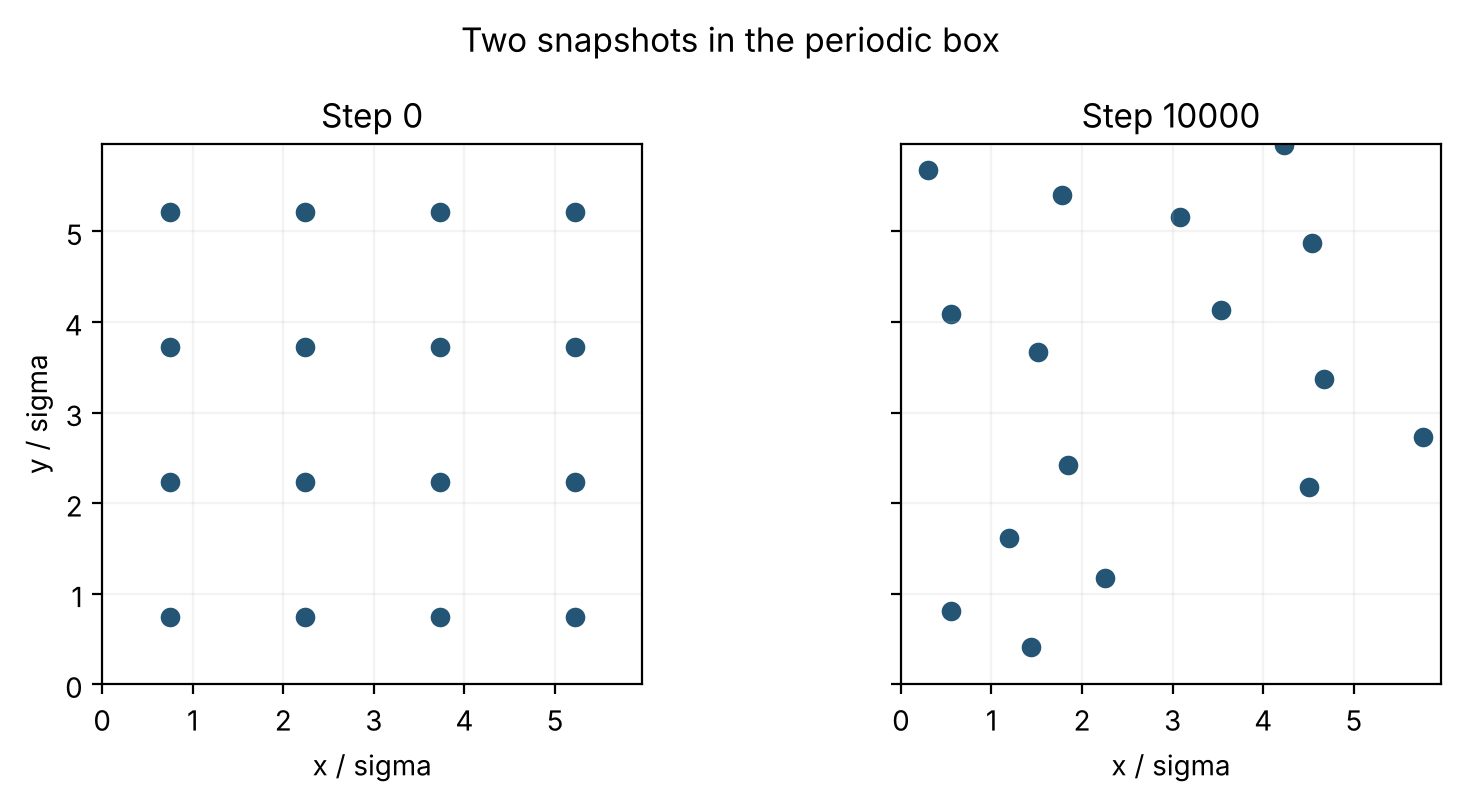

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 4.0), sharex=True, sharey=True)  # Create a figure with 2 side-by-side subplots sharing identical x and y axis scale limits
for ax, step in zip(axes, (0, results['n_steps'])):  # Loop through each subplot axis and snapshot step (dynamically pulls step 0 and step 10000 from results)
    points = results['snapshots'][step]  # Retrieve the (16, 2) position array corresponding to the current snapshot step
    ax.scatter(points[:, 0], points[:, 1], s=65, color='#245575',  # Plot particle x and y coordinates with size 65 in blue-grey
               edgecolor='white')  # Add a white border around each scatter point for visual clarity
    ax.set(xlim=(0, box_length), ylim=(0, box_length),  # Set plot boundaries to mirror the simulation box dimensions [0, L]
           title=f'Step {step}', xlabel='x / sigma')  # Set dynamic step title (Step 0 and Step 10000) and x-axis label
    ax.set_aspect('equal')  # Enforce 1:1 aspect ratio so the square simulation box is rendered without distortion
    ax.grid(alpha=0.15)  # Overlay a light background grid with 15% opacity
axes[0].set_ylabel('y / sigma')  # Add y-axis label to the leftmost subplot (applies to both via shared y-axis)
fig.suptitle('Two snapshots in the periodic box')  # Set the overarching figure title centered above both subplots
fig.tight_layout()  # Automatically pad and arrange subplots to prevent overlapping text
plt.show()  # Display the completed snapshot comparison plot

The mechanical energy is $E=K+U$. In an ideal isolated system, total energy is constant even though kinetic and potential energy exchange. Numerical integration introduces errors, so we monitor $E(t)$ rather than assuming conservation. The temperature curve can fluctuate while total energy remains nearly constant.


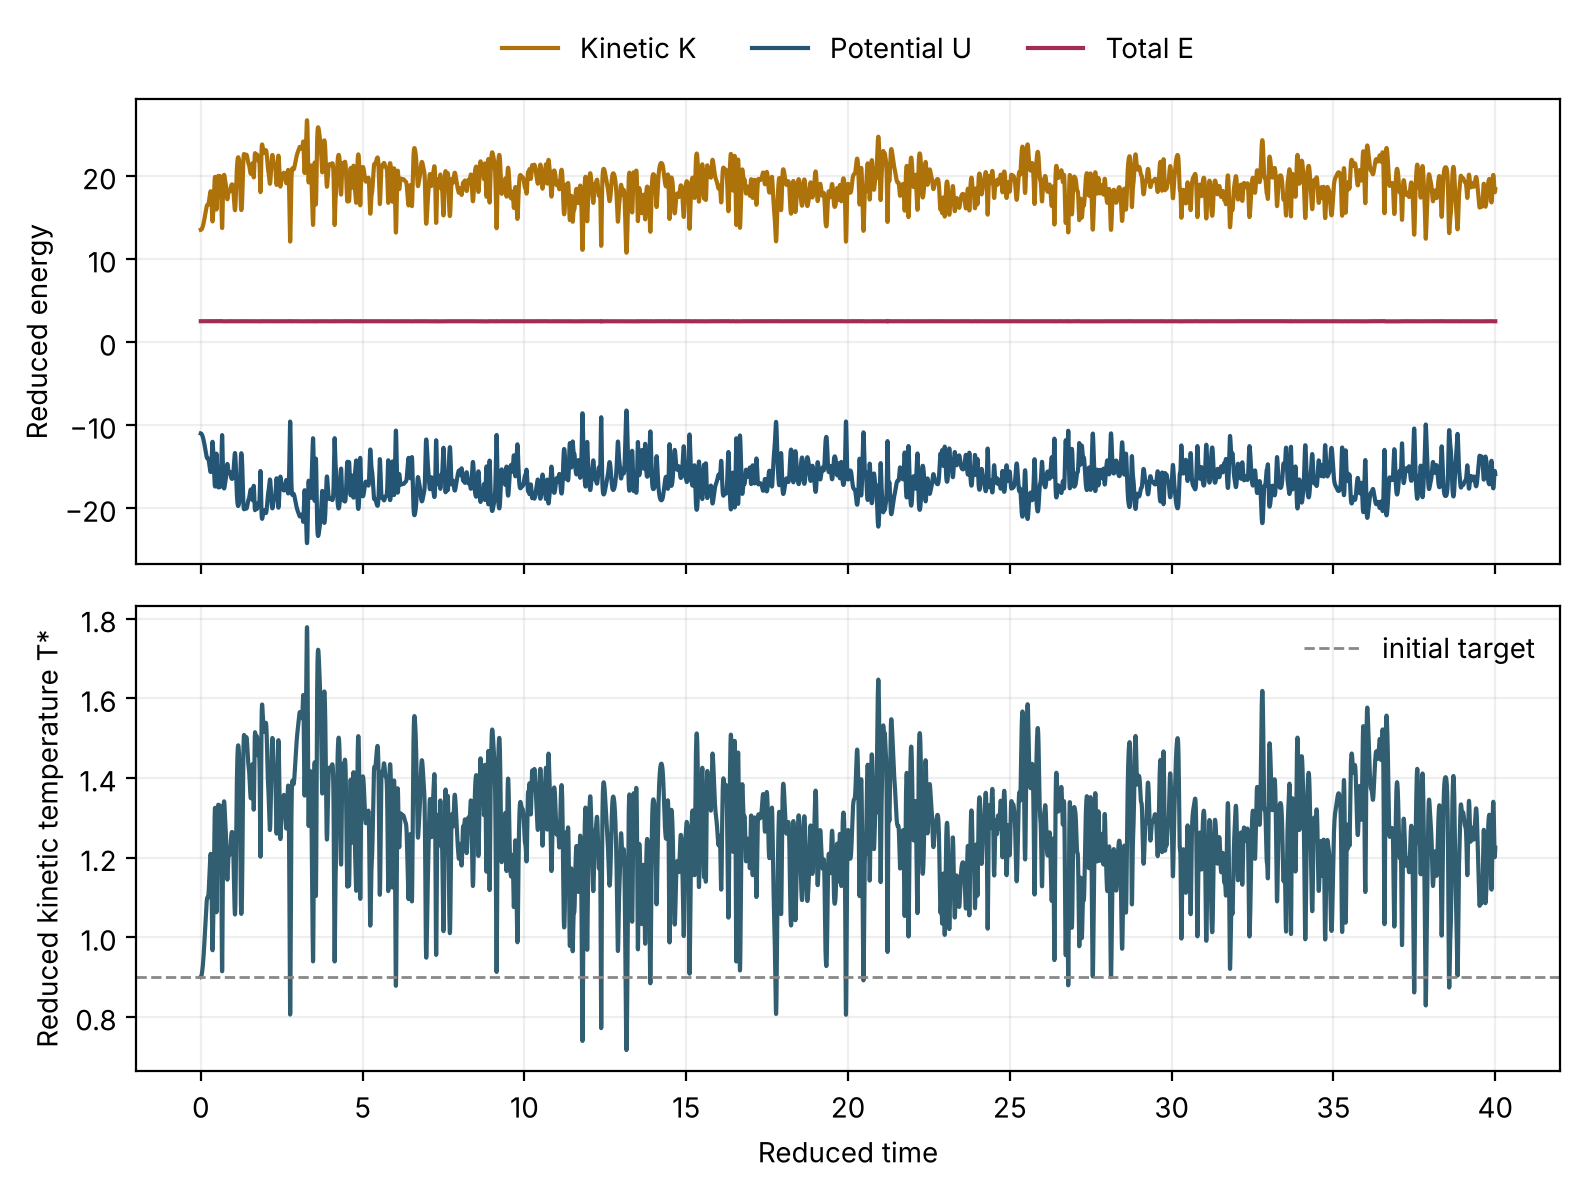

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(8.0, 6.0), sharex=True)  # Create 2 vertically stacked subplots (2 rows, 1 col) sharing a common x-axis (time)
axes[0].plot(results['time'], results['kinetic'], label='Kinetic K', color='#ae720b')  # Plot kinetic energy over the 10,000-step trajectory (t = 0 to 40.0) in gold
axes[0].plot(results['time'], results['potential'], label='Potential U', color='#245575')  # Plot potential energy over time in blue-grey
axes[0].plot(results['time'], results['total'], label='Total E', color='#a12c56')  # Plot total energy (K + U) over time in maroon to verify energy conservation
axes[0].set_ylabel('Reduced energy')  # Set the y-axis label for the top energy trajectory subplot
axes[0].legend(  # Position a 3-column borderless legend horizontally centered above the top subplot
    loc='upper center',
    bbox_to_anchor=(0.5, 1.20),
    ncol=3,
    frameon=False
)
axes[1].plot(results['time'], results['temperature'], color='#315e70')  # Plot instantaneous kinetic temperature T* over the 10,000-step trajectory
axes[1].axhline(initial_temperature, color='#888888', linestyle='--',  # Draw a dashed reference line across the full time range at initial target T* = 0.90
                linewidth=1, label='initial target')
axes[1].set(xlabel='Reduced time', ylabel='Reduced kinetic temperature T*')  # Set x-axis (reduced time) and y-axis labels for the lower subplot
axes[1].legend(frameon=False)  # Display borderless legend on the temperature subplot
for ax in axes:  # Loop through both subplot axes
    ax.grid(alpha=0.2)  # Overlay a faint background grid with 20% opacity on each plot
fig.tight_layout()  # Adjust layout spacing to ensure clear separation between subplots and legends
plt.show()  # Render and display the energy and temperature time-series plots

## 8. Basic analysis of the generated data

We treat the second half of the run as an **illustrative analysis window**. This is a convenient teaching choice, not a proof that the system has equilibrated. Mean, sample standard deviation, minimum, and maximum summarize the recorded instantaneous kinetic temperatures. Consecutive MD samples are correlated, so their sample SD measures the spread in this time series; it is **not** automatically the uncertainty of the mean. We report mean $U/N$ and $K/N$ to compare energies per particle.

For a simple integration diagnostic, calculate

$$D=\frac{\max_t |E(t)-E(0)|}{\max(|E(0)|,1)}\times100\%.$$

This normalized maximum energy deviation is **not** an experimental error bar or a measure of temperature uncertainty. A nonzero value reflects numerical integration and, in our finite-cutoff model, a possible contribution from the discontinuity of the force at $r_c$. Its size should be examined when changing the time step.


In [24]:
window_start = len(results['time']) // 2  # Calculate starting index for second half of trajectory (step 5000 for 10,000 steps) for equilibrium analysis
later_temperature = results['temperature'][window_start:]  # Slice temperature history for the second half of the run (steps 5000 to 10000)
later_kinetic = results['kinetic'][window_start:]  # Slice kinetic energy history for the second half of the run
later_potential = results['potential'][window_start:]  # Slice potential energy history for the second half of the run
energy_reference = results['total'][0]  # Store total initial energy as a reference baseline for energy conservation checks
max_energy_deviation = np.max(np.abs(results['total'] - energy_reference))  # Calculate maximum absolute variation in total energy across all 10,000 steps
# Compute maximum percentage deviation in total energy relative to reference energy
energy_deviation_percent = 100 * max_energy_deviation / max(abs(energy_reference), 1.0)

summary = {  # Create dictionary compiling equilibrium summary statistics and run parameters
    'seed': results['seed'],  # Store random seed used for velocity generation
    'particles': particle_count,  # Store total particle count in system (N = 16)
    'steps': results['n_steps'],  # Store total number of integration steps (10,000 steps)
    'mean_T_star': statistics.mean(later_temperature),  # Compute mean reduced temperature T* over equilibrium window
    'sample_SD_T_star': statistics.stdev(later_temperature),  # Compute sample standard deviation of T* over equilibrium window
    'minimum_T_star': min(later_temperature),  # Identify minimum instantaneous temperature during equilibrium window
    'maximum_T_star': max(later_temperature),  # Identify maximum instantaneous temperature during equilibrium window
    'mean_K_per_particle': statistics.mean(later_kinetic) / particle_count,  # Compute mean kinetic energy per particle (<K>/N)
    'mean_U_per_particle': statistics.mean(later_potential) / particle_count,  # Compute mean potential energy per particle (<U>/N)
    'max_energy_deviation_percent': energy_deviation_percent,  # Store maximum percent energy drift over entire 10,000-step run
}
for label, value in summary.items():  # Iterate over each key-value pair in summary dictionary
    print(f'{label:30s} {value:.5f}' if isinstance(value, float)  # Format float metrics to 5 decimal places with left-aligned label (width 30)
          else f'{label:30s} {value}')  # Print non-float parameters (seed, particles, steps) as standard formatted strings

seed                           2026
particles                      16
steps                          10000
mean_T_star                    1.25840
sample_SD_T_star               0.12927
minimum_T_star                 0.82837
maximum_T_star                 1.64683
mean_K_per_particle            1.17975
mean_U_per_particle            -1.02362
max_energy_deviation_percent   1.07688


### Efficient computing E8: use the right tool for bulk data

The `statistics` module used above is part of standard Python. It is general and careful (it works with exact fractions internally), but it processes the numbers one at a time in Python. NumPy's `np.mean` and `np.std` run compiled loops over the whole array. For 5001 recorded temperatures the difference is easy to measure. Note the argument `ddof=1` ("delta degrees of freedom"): it makes `np.std` divide by $n-1$, the **sample** standard deviation that `statistics.stdev` computes. Without it, `np.std` divides by $n$, which is a common source of small mismatches between programs.

In [25]:
n_repeats = 50  # Repeat each calculation to get a measurable time
# Average time for mean and sample standard deviation with the statistics module
time_statistics = timeit.timeit(lambda: (statistics.mean(later_temperature), statistics.stdev(later_temperature)), number=n_repeats) / n_repeats
# Average time for the same two quantities with NumPy (ddof=1 gives the sample SD)
time_numpy = timeit.timeit(lambda: (np.mean(later_temperature), np.std(later_temperature, ddof=1)), number=n_repeats) / n_repeats
# Report the statistics-module time in milliseconds
print(f'statistics module: {1000 * time_statistics:8.3f} ms')
# Report the NumPy time and the speed-up
print(f'NumPy:             {1000 * time_numpy:8.3f} ms   ({time_statistics / time_numpy:.0f} x faster)')

# Check that both libraries give the same mean
print('Same mean?              ', math.isclose(statistics.mean(later_temperature), np.mean(later_temperature)))
# Check the sample standard deviation (ddof=1, divide by n - 1)
print('Same sample SD (ddof=1)?', math.isclose(statistics.stdev(later_temperature), np.std(later_temperature, ddof=1)))
# With ddof=0 NumPy divides by n, so the results differ slightly: prints False
print('Same with ddof=0?       ', math.isclose(statistics.stdev(later_temperature), np.std(later_temperature)))

statistics module:    4.735 ms
NumPy:                0.020 ms   (238 x faster)
Same mean?               True
Same sample SD (ddof=1)? True
Same with ddof=0?        False


For a single summary of 5001 numbers, a few milliseconds hardly matter, and the `statistics` module remains a fine choice. The difference matters when the same calculation is repeated thousands of times, for example inside a loop over many runs or many particles.

The histogram below shows a distribution of instantaneous kinetic-temperature estimates in our chosen time window. It is a descriptive graph of one finite, correlated trajectory. Changing the number of bins changes its appearance. It should not be presented as a measured temperature distribution for a real material.


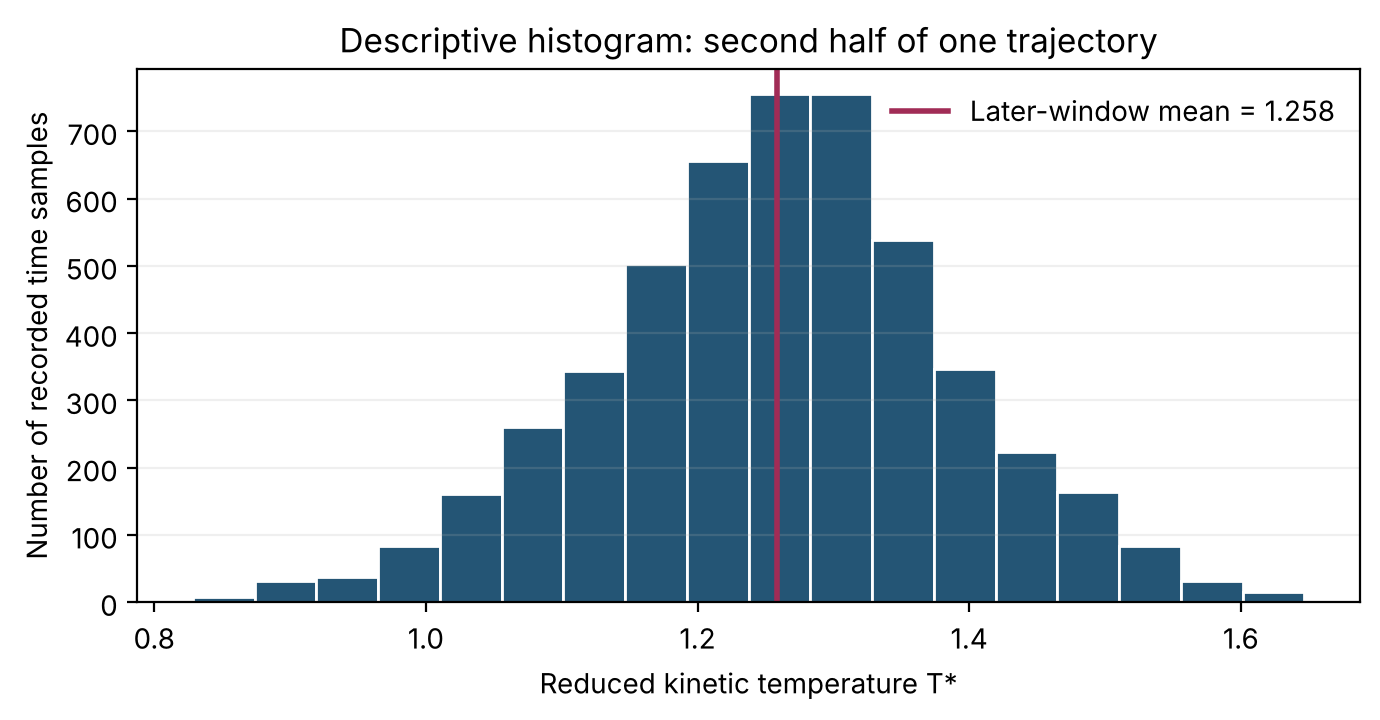

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.7))  # Create a figure and axis object with dimensions 7x3.7 inches
ax.hist(later_temperature, bins=18, color='#245575', edgecolor='white')  # Plot histogram of equilibrium temperature values (steps 5,000–10,000) using 18 bins with white bar borders
ax.axvline(summary['mean_T_star'], color='#a12c56', linewidth=2,  # Draw a vertical reference line at the equilibrium mean temperature in maroon
           label=f"Later-window mean = {summary['mean_T_star']:.3f}")  # Add legend label showing mean T* formatted to 3 decimal places
ax.set(xlabel='Reduced kinetic temperature T*',  # Set x-axis label for reduced temperature
       ylabel='Number of recorded time samples',  # Set y-axis label for frequency of recorded time samples
       title='Descriptive histogram: second half of one trajectory')  # Set main title for histogram
ax.legend(frameon=False)  # Display the legend without a surrounding frame box
ax.grid(axis='y', alpha=0.2)  # Enable horizontal y-axis grid lines with 20% opacity for easy count reading
fig.tight_layout()  # Automatically adjust layout parameters so labels and text fit cleanly
plt.show()  # Display the completed temperature distribution histogram

## 9. Check reproducibility and a physical invariant

The first test reruns the model with the same seed, the same settings **and the same force routine** as `results_fast` from Section 6. A separate NumPy generator is created inside each call, so the complete temperature histories should match bit for bit. (Section 6 showed that a different, equally correct force routine gives a different long trajectory; exact reproducibility is a property of the program, not only of the equations.) The second test checks the total force at a displaced configuration: internal pair forces must sum to (approximately) zero because of Newton's third law. These are useful **code checks**; they do not prove that the physical model represents a real fluid.


In [27]:
repeat = run_md(seed=2026, time_step=0.004, n_steps=10000,  # Re-run with the identical seed, settings ...
                force_function=forces_and_potential_fast)  # ... and force routine as results_fast
same_history = np.array_equal(results_fast['temperature'], repeat['temperature'])  # Compare temperature history arrays element-by-element for exact equality
test_positions = results['snapshots'][results['n_steps']]  # Retrieve particle position snapshot at final step (step 10,000)
test_forces, _ = forces_and_potential(test_positions, box_length)  # Recompute forces acting on particles at final positions
net_force_norm = np.linalg.norm(test_forces.sum(axis=0))  # Calculate magnitude (Euclidean norm) of net system force vector across x and y

print('Identical complete temperature history:', same_history)  # Output boolean result confirming deterministic reproducibility
print('Norm of net internal force:', f'{net_force_norm:.3e}')  # Output net force magnitude formatted in scientific notation
assert same_history  # Raise error if duplicate run temperature trajectory does not match original exactly
assert net_force_norm < 1e-10  # Raise error if net internal system force deviates from zero (verifying Newton's Third Law)

Identical complete temperature history: True
Norm of net internal force: 4.606e-15


## 10. Guided questions and small experiments

1. **Trace a variable.** What is the shape of `starting_positions`? What does `starting_positions[3]` represent? Why is `len(results['time'])` one greater than `n_steps`?
2. **Trace a loop.** How many distinct pairs does `forces_and_potential` inspect for 16 particles? Use $N(N-1)/2$ to check your answer. Why does its inner loop start at `i + 1`?
3. **Explain a conditional.** What error does the `if distance_squared < 0.09` statement catch? Would removing it improve the physics?
4. **Interpret the graph.** Does a rise in kinetic energy require a rise in total energy? Point to a segment of the energy graph that supports your answer.
5. **Change the seed.** Run `alternate = run_md(seed=2027)`. Compare its later-window mean temperature with `summary['mean_T_star']`. Does a seed change the interaction law, or only the starting velocities?
6. **Change the time step.** Try `coarser = run_md(seed=2026, time_step=0.008, n_steps=5000)`, which keeps the same final time ($t=40$). Compare the maximum energy deviation with the baseline. A numerical trend in one run is a diagnostic, not a universal guarantee.
7. **Count the arrays.** Between steps, which arrays of shape `(16, 2)` does `run_md` keep? Predict what would happen to `starting_positions` if `run_md` began with `positions = starting_positions` (no `.copy()`). Test the prediction on a short run, then restore the line and use *Run All* again.
8. **Predict a run time.** Use the timings in E7 to estimate how long one call of `forces_and_potential_fast` takes for $N=1000$, and a 10 000-step run. Check the single call by building a $32\times32$ lattice (about 1000 particles) as in E7.
9. **Profile before optimising.** Use `timeit` to time `kinetic_energy(starting_velocities)` and compare it with one force call. Would rewriting `kinetic_energy` noticeably speed up `run_md`? Explain using E5.

Run the following optional code cell to begin Questions 5 and 6. It uses the faster force routine from Section 6. It does not change the original `results` dictionary.


In [28]:
alternate = run_md(seed=2027, force_function=forces_and_potential_fast)  # Different random seed (2027); default 10,000 steps (dt=0.004, t=40.0)
coarser = run_md(seed=2026, time_step=0.008, n_steps=5000,  # Larger time step dt=0.008; 5,000 steps reach the same final time t=40.0
                 force_function=forces_and_potential_fast)  # Same force routine as results_fast, the baseline below


def max_deviation_percent(data):  # Define helper function to calculate maximum percentage energy conservation drift
    reference = data['total'][0]  # Store initial total energy as baseline reference value
    # Calculate max relative deviation in total energy expressed as a percentage
    return (100 * np.max(np.abs(data['total'] - reference))) / max(
        abs(reference), 1.0
    )


print(
    'Baseline mean T*, later half: ', f"{summary['mean_T_star']:.3f}"
)  # Display baseline equilibrium mean temperature T* (dt=0.004)
print(
    'New seed mean T*, later half:',  # Display equilibrium mean temperature for alternate seed (seed 2027) run
    f"{statistics.mean(alternate['temperature'][len(alternate['time']) // 2 :]):.3f}",
)
print(
    'Baseline max E deviation (%):', f'{max_deviation_percent(results_fast):.4f}'
)  # Maximum percentage energy deviation, dt = 0.004 (same force routine)
print(
    'Coarser max E deviation (%): ', f'{max_deviation_percent(coarser):.4f}'
)  # Maximum percentage energy deviation, dt = 0.008 (one comparison cannot by itself establish a scaling law)

Baseline mean T*, later half:  1.258
New seed mean T*, later half: 1.263
Baseline max E deviation (%): 1.4461
Coarser max E deviation (%):  6.2836


In this example, changing the seed changes the later-window mean even though the force law is unchanged. Doubling the time step produces a larger energy deviation over approximately the same duration. One comparison is a useful diagnostic, but a careful numerical study would examine more time steps and longer trajectories.


## 11. Efficient computing: a checklist

| Habit | Where | What it saved in this notebook |
|:--|:--|:--|
| Work in reduced units | E1 | Fewer operations per pair; no underflow in single precision |
| Build the 12-6 potential from $r^2$; never take a square root you do not need | E2 | About 2× faster in a pure-Python loop |
| Start from a lattice | E3 | No dangerous overlaps; $N$ placements instead of a trial-and-error search |
| Overwrite arrays you no longer need (in-place updates) | E4 | Three state arrays instead of four or five |
| Compute once and reuse; move loop-invariant work out of loops | E4 | One kinetic-energy evaluation per step instead of two |
| Measure before optimising | E5 | Showed that nearly all of the run time is spent on forces |
| Avoid NumPy calls on tiny arrays inside loops | E5 | About 10× faster force routine, same physics |
| Re-verify optimised code; compare averages, not chaotic trajectories | E6 | Agreement to round-off per call |
| Know how the cost scales with problem size | E7 | All pairs: $O(N^2)$; cell lists: $O(N)$ |
| Use NumPy for bulk data | E8 | About 100× faster mean and SD (or more) |

The speed-ups were measured on the computer used to prepare this notebook; yours will differ, but the direction should be the same. Two further routes, beyond this course, are worth knowing by name: **vectorisation** (expressing the whole pair calculation as operations on large arrays, so that NumPy's compiled loops do the work) and **compilation** (tools such as Numba, or writing the inner loop in C or Fortran), which is how programs such as LAMMPS and GROMACS reach millions of atoms.

## 12. What this model does and does not show

This exercise uses identical, structureless particles in two spatial dimensions, periodic boundaries, a simple pair force, and a small number of steps. Its density is per **area**, and the kinetic-temperature formula is specific to 2D. There is no thermostat, no pressure calculation, no chemical detail, and no calibration to a particular substance. The short trajectory and an arbitrary later-window average do not establish equilibrium, independent samples, or a physical phase. Total-energy monitoring and reproducibility checks address implementation quality, not experimental validity. The all-pairs force loop in pure Python is adequate for 16 particles but, as E7 shows, not for large systems; production codes use neighbour lists and compiled, vectorised or GPU code.

For further reading, consult the official [LAMMPS Lennard-Jones potential documentation](https://docs.lammps.org/pair_lj.html), its [velocity-Verlet NVE integrator documentation](https://docs.lammps.org/fix_nve.html), and the [GROMACS discussion of kinetic temperature and removed centre-of-mass degrees of freedom](https://manual.gromacs.org/documentation/2026.0/reference-manual/algorithms/molecular-dynamics.html). Professional MD packages offer many additional features. Our 2D, finite-cutoff implementation and its unit convention are specified above so that every calculation remains visible to a beginning programmer.
